### Late prediction using ML

**Dataset:** DataCo Smart Supply Chain — 180,519 orders, 53 features

# 0. Install

In [ ]:
!pip install pandas numpy scikit-learn xgboost matplotlib seaborn joblib tensorflow

# 1. Imports

In [ ]:
import time
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-darkgrid')
import unicodedata
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier , callback
from sklearn.metrics import roc_auc_score, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.metrics import AUC
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 2. Load Data

In [ ]:
df_raw = pd.read_csv('/content/DataCoSupplyChainDataset.csv', encoding='latin-1')
df = df_raw.copy()

In [ ]:
df.shape

(180519, 53)

# 3. Initial Exploration

In [ ]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

### Business Domains and Pain Points

| Domain        | Common Business Pain Points                                      |
|---------------|------------------------------------------------------------------|
| Supply Chain  | Late deliveries, demand forecasting, fraud, inventory loss       |
| Finance       | Fraud detection, profit prediction                               |
| Logistics     | Shipping delays, route optimization                              |

### Question

**What would a supply chain company lose money on?**

A supply chain company can lose money due to:
- Late deliveries  
- Fraud  
- Unpredicted demand  

## 3.1. Target Variable Identification

In [ ]:
# See all columns and their data types
df.dtypes.reset_index().rename(columns={'index':'Column', 0:'Type'})

# Check columns with binary values (0/1) for finding out target
binary_cols = [col for col in df.columns if df[col].nunique() == 2]
print("Binary columns (0/1) :", binary_cols)
target = "Late_delivery_risk"
df[target].unique()

# Check columns with few unique values for classification
low_unique = [col for col in df.columns if df[col].nunique() <= 6]
print("Low unique values columns (Classification targets):", low_unique)

# Check fully numeric columns for regression
numeric_cols = df.select_dtypes(include='number').columns.tolist()
print("Numeric columns (regression targets):", numeric_cols)

Binary columns (0/1) : ['Late_delivery_risk', 'Customer Country']
Low unique values columns (Classification targets): ['Type', 'Days for shipment (scheduled)', 'Delivery Status', 'Late_delivery_risk', 'Customer Country', 'Customer Email', 'Customer Password', 'Customer Segment', 'Market', 'Order Item Quantity', 'Product Description', 'Product Status', 'Shipping Mode']
Numeric columns (regression targets): ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Price', 'Product Stat

In [ ]:
def data_info(data):
    print('- Number of columns are : ',data.shape[1])
    print('- Number of rows are : ',data.shape[0])
    print('- Total number of data-points :',data.size)
    numerical_features = [f for f in data.columns if data[f].dtypes!='O']
    print('- Count of Numerical Features :',len(numerical_features))
    cat_features = [c for c in data.columns if data[c].dtypes=='O']
    print('- Count of Categorical Features :',len(cat_features))

data_info(df)

- Number of columns are :  53
- Number of rows are :  180519
- Total number of data-points : 9567507
- Count of Numerical Features : 29
- Count of Categorical Features : 24


In [ ]:
df.isnull().sum(axis = 0)

,0
Type,0
Days for shipping (real),0
Days for shipment (scheduled),0
Benefit per order,0
Sales per customer,0
Delivery Status,0
Late_delivery_risk,0
Category Id,0
Category Name,0
Customer City,0


In [ ]:
df.isnull().sum(axis = 1)


,0
0,2
1,2
2,2
3,2
4,2
...,...
180514,2
180515,2
180516,2
180517,2


In [ ]:
def missing_values_table(df):
    mis_val = df.isnull().sum()
    mis_val_percent = 100 * df.isnull().sum() / len(df)
    mis_val_table = pd.concat([mis_val, mis_val_percent], axis=1)
    mis_val_table_rename_columns = mis_val_table.rename(
    columns = {0 : 'Missing Values', 1 : '% of Total Values'})
    mis_val_table_rename_columns = mis_val_table_rename_columns[
        mis_val_table_rename_columns.iloc[:,1] != 0].sort_values(
    '% of Total Values', ascending=False).round(1)
    print ("Your selected dataframe has " + str(df.shape[1]) + " columns.\n"
        "There are " + str(mis_val_table_rename_columns.shape[0]) +
            " columns that have missing values.")
    return mis_val_table_rename_columns

missing_values_table(df)


Your selected dataframe has 53 columns.
There are 4 columns that have missing values.


,Missing Values,% of Total Values
Product Description,180519,100.0
Order Zipcode,155679,86.2
Customer Lname,8,0.0
Customer Zipcode,3,0.0


# 4. Correlation & Duplicate Analysis

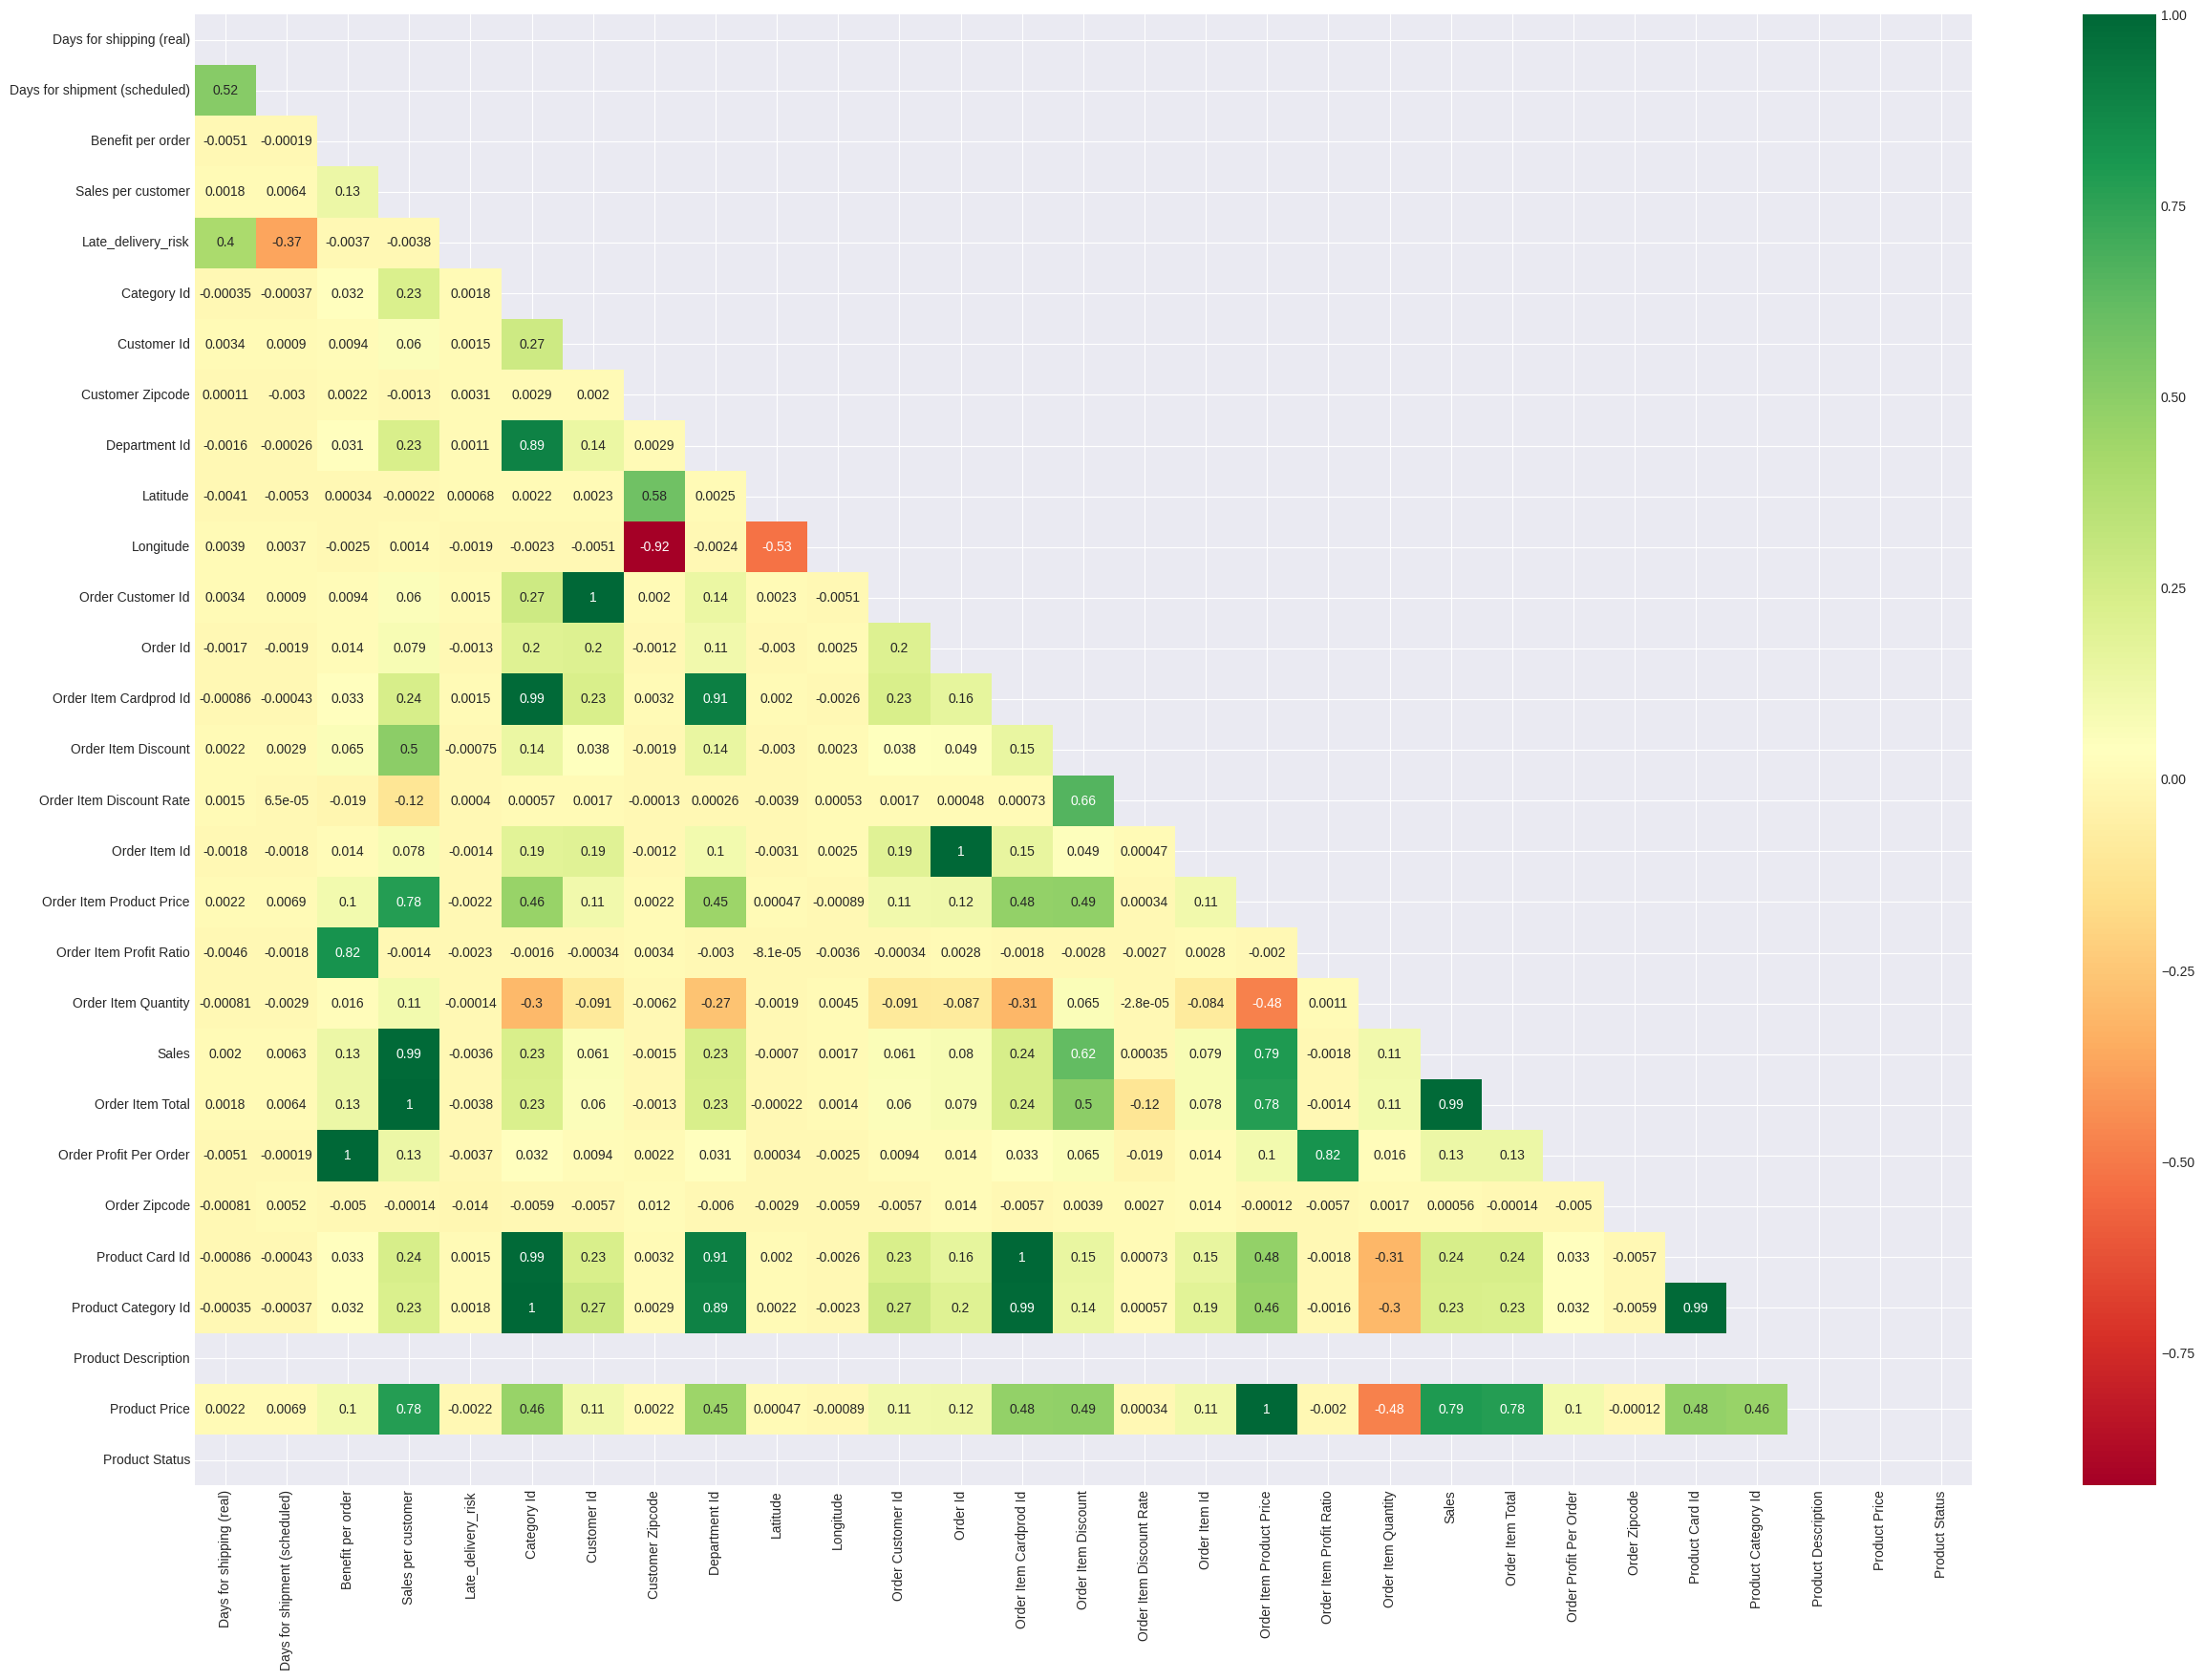

In [ ]:
corrmap = df.corr(numeric_only=True)
top = corrmap.index

# mask for the upper triangle
mask = np.triu(np.ones_like(corrmap, dtype=bool))
plt.figure(figsize=(30,20))
g = sns.heatmap(df[top].corr(numeric_only=True), annot=True, cmap="RdYlGn", mask=mask)
plt.show()

### Insights from the Heatmap

#### 1. Duplicate or Redundant Columns
Some columns contain the same or very similar values but have different names due to metadata differences. These columns should be reviewed before model building.

- `Benefit per order` and `Order Profit per order`
- `Sales per customer`, `Sales`, and `Order Item Total`
- `Category ID`, `Product Category ID`, `Order Customer ID`, `Order Item Category ID`, and `Product Card ID`
- `Order Item Product Price` and `Product Price`

#### 2. Unwanted Features
Some features appear to be less useful because they contain many null values or show weak correlation with other variables.

- `Product Description`
- `Product Status`

These features can be considered for removal during preprocessing if they do not provide meaningful information for analysis or prediction.

In [ ]:
numerical_features = [f for f in df.columns if df[f].dtypes!='O']
cat_features = [c for c in df.columns if df[c].dtypes=='O']
print("Numerical: ",numerical_features)
print("Categorical: ",cat_features)

Numerical:  ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Late_delivery_risk', 'Category Id', 'Customer Id', 'Customer Zipcode', 'Department Id', 'Latitude', 'Longitude', 'Order Customer Id', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Price', 'Product Status']
Categorical:  ['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Department Name', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Region', 'Order State', 'Order Status', 'Product Image', 'Product Name

In [ ]:
# ── Check relationships ────────────────────────────────
checks = {
    "Sales per customer == Sales": (df['Sales per customer'], df['Sales']),
    "Order Item Total == Sales": (df['Order Item Total'], df['Sales']),
    "Discount == Price * Discount Rate": (df['Order Item Discount'], df['Order Item Product Price'] * df['Order Item Discount Rate']),
    "Order Item Total == Sales - Discount": (df['Order Item Total'], df['Sales'] - df['Order Item Discount']),
    "Profit Ratio == Profit Per Order / Sales": (df['Order Item Profit Ratio'], df['Order Profit Per Order'] / df['Sales']),
}
for name, (a, b) in checks.items():
    print(f"{name}? {np.allclose(a, b, atol=0.01)}") # check if all elements between two arrays are equal within a specified numerical tolerance(0.01 max)

# ── Perfect correlations ──────────────────────────────────────────
corr = df.select_dtypes(include=np.number).drop(columns=['Late_delivery_risk']).corr().abs()
print("\n── Perfect correlations (1.0) ──")
for col in corr.columns:
    perfect = corr[col][(corr[col] == 1.0) & (corr.index != col)]
    if not perfect.empty:
        print(f"{col} ←→ {perfect.index.tolist()}")


Sales per customer == Sales? False
Order Item Total == Sales? False
Discount == Price * Discount Rate? False
Order Item Total == Sales - Discount? True
Profit Ratio == Profit Per Order / Sales? False

── Perfect correlations (1.0) ──
Benefit per order ←→ ['Order Profit Per Order']
Sales per customer ←→ ['Order Item Total']
Category Id ←→ ['Product Category Id']
Customer Id ←→ ['Order Customer Id']
Order Customer Id ←→ ['Customer Id']
Order Item Cardprod Id ←→ ['Product Card Id']
Order Item Product Price ←→ ['Product Price']
Order Item Total ←→ ['Sales per customer']
Order Profit Per Order ←→ ['Benefit per order']
Product Card Id ←→ ['Order Item Cardprod Id']
Product Category Id ←→ ['Category Id']
Product Price ←→ ['Order Item Product Price']


# 5. Drop Columns

In [ ]:
# PII : Personally Identifiable Information
cols_to_drop = [
    'Product Description',       # 100% missing
    'Order Zipcode',             # 86% missing
    'Product Image',             # URL, no value
    'Customer Email',            # PII, no predictive use
    'Customer Password',         # PII
    'Customer Fname',            # PII
    'Customer Lname',            # PII
    'Customer Street',           # PII

    # Exact duplicates (confirmed from correlation heatmap)
    'Order Item Cardprod Id',    # same as Product Card Id
    'Product Category Id',       # same as Category Id
    'Order Customer Id',         # same as Customer Id
    'Category Id',               # Category Name is more informative
    'Department Id',             # Department Name is more informative

    # Only known after delivery — leakage

    'Delivery Status',           # directly encodes target
    'Order Status',              # COMPLETE/CLOSED = post-delivery leakage
    'shipping date (DateOrders)',# post-order info

    # IDs — random sequential, no predictive signal
    'Order Id',
    'Order Item Id',

    # Covered by Latitude & Longitude (both = store location)
    'Customer City',             # store location
    'Customer State',            # store location similar
    'Customer Country',          # similar
    'Customer Zipcode',          # similar

    # Confirmed mathematical duplicates
    'Product Price',             # exact copy of Order Item Product Price
    'Benefit per order',         # exact copy of Order Profit Per Order
    'Order Item Total',          # derivable: Sales - Order Item Discount
    'Sales per customer',        # perfect correlation with Order Item Total
]

df.drop(columns=cols_to_drop, inplace=True, errors='ignore')
print(f"After dropping: {df.shape}")
print(df.columns.tolist())


After dropping: (180519, 27)
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Late_delivery_risk', 'Category Name', 'Customer Id', 'Customer Segment', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'order date (DateOrders)', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Profit Per Order', 'Order Region', 'Order State', 'Product Card Id', 'Product Name', 'Product Status', 'Shipping Mode']


In [ ]:
#DateOrder leakage
df["order date (DateOrders)"] = pd.to_datetime(df["order date (DateOrders)"])
df["order_year"] = (df["order date (DateOrders)"].dt.year)

df["order_month"] = (
    df["order date (DateOrders)"].dt.month
)

df["order_dayofweek"] = (
    df["order date (DateOrders)"].dt.dayofweek
)

df["order_quarter"] = (
    df["order date (DateOrders)"].dt.quarter
)
df = df.drop(
    columns=["order date (DateOrders)"]
)

In [ ]:
df.shape

(180519, 30)

In [ ]:
audit = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique().values,
    "missing": df.isnull().sum().values
})
audit.sort_values("n_unique", ascending=False)

,column,dtype,n_unique,missing
Order Profit Per Order,Order Profit Per Order,float64,21998,0
Customer Id,Customer Id,int64,20652,0
Latitude,Latitude,float64,11250,0
Longitude,Longitude,float64,4487,0
Order City,Order City,object,3597,0
Order State,Order State,object,1089,0
Order Item Discount,Order Item Discount,float64,1017,0
Sales,Sales,float64,193,0
Order Country,Order Country,object,164,0
Order Item Profit Ratio,Order Item Profit Ratio,float64,162,0


# 6. Data Cleaning

In [ ]:
# True/False mask for the whole DataFrame
# This checks if each cell contains any character outside the standard ASCII range
mask = df.apply(lambda col: col.astype(str).str.contains(r'[^\x00-\x7F]', na=False))

# Filter to see any row that has AT LEAST ONE non-ASCII character in any column
non_ascii_rows = df[mask.any(axis=1)]
special_counts = mask.sum()
print(special_counts[special_counts > 0])



Order City       15208
Order Country    37430
Order State      35310
dtype: int64


In [ ]:
def clean_text(x):
    if x == 'nan':
        return x
    return unicodedata.normalize('NFKD', str(x)).encode('ascii', errors='ignore').decode('ascii').strip()

text_cols = df.select_dtypes(include='object').columns.tolist()
for col in text_cols:
    df[col] = df[col].apply(clean_text)

In [ ]:
# Final check before EDA
print("Shape:", df.shape)
print("\nDtypes:")
print(df.dtypes.value_counts())

print("\nNull check:", df.isnull().sum().sum(), "nulls")

print("\nTarget balance:")
print(df['Late_delivery_risk'].value_counts(normalize=True).round(3))


Shape: (180519, 30)

Dtypes:
object     11
float64     8
int64       7
int32       4
Name: count, dtype: int64

Null check: 0 nulls

Target balance:
Late_delivery_risk
1    0.548
0    0.452
Name: proportion, dtype: float64


# 7. Exploratory Data Analysis

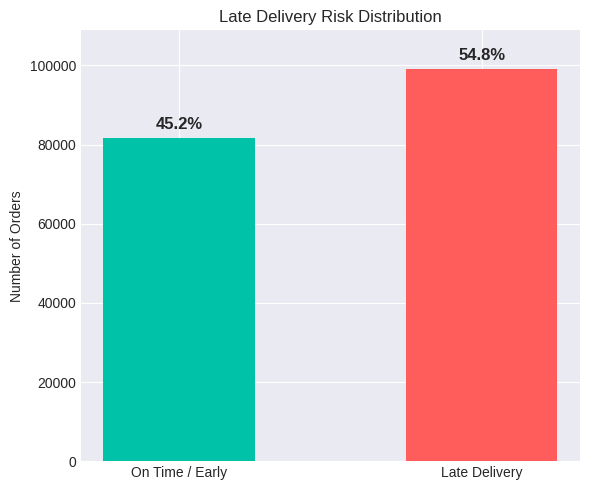

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))

counts = df['Late_delivery_risk'].value_counts().sort_index()
labels = ['On Time / Early', 'Late Delivery']
bars = ax.bar(labels, counts, color=['#00C2A8', '#FF5C5C'], width=0.5)
total = len(df)
ax.bar_label(bars,
             labels=[f'{val/total:.1%}' for val in counts],
             padding=5,
             fontsize=12,
             fontweight='bold')

ax.set(title='Late Delivery Risk Distribution', ylabel='Number of Orders')
ax.spines[['top', 'right']].set_visible(False) #lines connecting the axis tick marks, defining the boundaries of a data area
ax.margins(y=0.1) # Prevents label cutoff

plt.tight_layout()
plt.show()

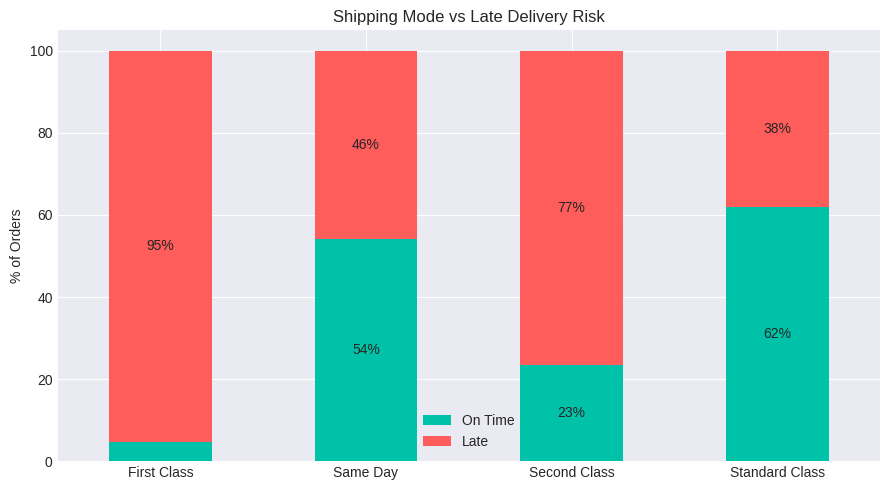

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

# Prepare data
mode_risk = df.groupby('Shipping Mode')['Late_delivery_risk'] \
              .value_counts(normalize=True).unstack() * 100
mode_risk.columns = ['On Time', 'Late']

# Plot
mode_risk.plot(kind='bar', stacked=True, ax=ax,
               color=['#00C2A8', '#FF5C5C'])

# Add labels for visible parts
for container in ax.containers:
    ax.bar_label(container,
                 labels=[f'{v:.0f}%' if v > 5 else '' for v in container.datavalues],
                 label_type='center')

ax.set(title='Shipping Mode vs Late Delivery Risk',
       xlabel='',
       ylabel='% of Orders')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Shipping Mode vs Late Delivery Risk

This chart shows the percentage of orders delivered **on time** versus **late** across different shipping modes.

### Key Insights

- **Standard Class** has the highest on-time delivery rate (62%).
- **Same Day** performs moderately well with a near 50/50 split.
- **Second Class** has a high late delivery rate (77%).
- **First Class** performs the worst, with **95% of orders delivered late**.

### Conclusion

Despite expectations, faster shipping methods like **First Class** show significantly higher late delivery risk, while **Standard Class** appears to be the most reliable option.

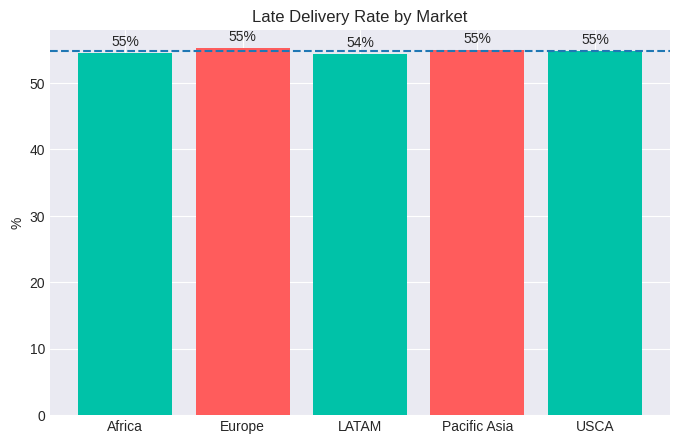

In [ ]:
rates = df.groupby('Market')['Late_delivery_risk'].mean() * 100
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#FF5C5C' if v > 55 else '#00C2A8' for v in rates]
bars = ax.bar(rates.index, rates, color=colors)

# Labels
ax.bar_label(bars, fmt='%.0f%%', padding=3)
ax.axhline(rates.mean(), ls='--', label=f'Avg: {rates.mean():.0f}%')
ax.set(title='Late Delivery Rate by Market', ylabel='%')
ax.spines[['top', 'right']].set_visible(False)

plt.show()

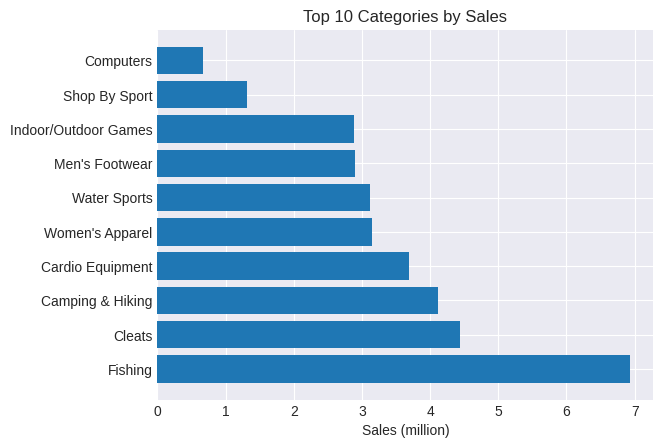

In [ ]:
fig, ax = plt.subplots()
top_cats = df.groupby('Category Name')['Sales'].sum().nlargest(10)
# Convert large sales numbers into millions (e.g., 5,000,000 → 5)
sales_millions = top_cats / 1e6

# Plot categories vs sales horizontal bars
bars = ax.barh(top_cats.index, sales_millions)
ax.set(title='Top 10 Categories by Sales', xlabel='Sales (million)')
plt.show()

### Top 10 Categories by Sales

This chart highlights the top-performing product categories based on total sales (in millions).

### Sales by Category

1. **Fishing** — 6.9M±  
2. **Cleats** — 4.5M±  
3. **Camping & Hiking** — 4.1M±  
4. **Cardio Equipment** — 3.7M±  
5. **Women's Apparel** — 3.1M±  
6. **Water Sports** — 3.1M±  
7. **Men's Footwear** — 2.9M±  
8. **Indoor/Outdoor Games** — 2.9M±  
9. **Shop By Sport** — 1.3M±  
10. **Computers** — 0.6M±  

### Key Insights

- **Fishing** dominates all categories with a significant lead in sales.
- **Cleats** and **Camping & Hiking** are strong mid-tier performers.
- Categories like **Women's Apparel**, **Water Sports**, and **Cardio Equipment** show steady sales.
- **Computers** and **Shop By Sport** have the lowest sales among the top 10.

### Conclusion

Outdoor and sports-related categories (e.g., **Fishing**, **Camping & Hiking**, **Cleats**) drive the highest revenue, indicating strong customer interest in sports and outdoor gear.

# 8. Feature Engineering

In [ ]:
if 'order date (DateOrders)' in df.columns:
    df['order_date'] = pd.to_datetime(df['order date (DateOrders)'])
    df['order_month']     = df['order_date'].dt.month
    df['order_dayofweek'] = df['order_date'].dt.dayofweek
    df['order_quarter']   = df['order_date'].dt.quarter
    df.drop(columns=['order date (DateOrders)', 'order_date'], inplace=True)

df['profit_margin'] = df['Order Profit Per Order'] / df['Sales'].replace(0, np.nan)

print(f"Shape: {df.shape}")
print(df[['order_month', 'order_dayofweek', 'order_quarter', 'profit_margin']].head(3))


Shape: (180519, 31)
   order_month  order_dayofweek  order_quarter  profit_margin
0            1                2              1       0.278413
1            1                5              1      -0.760000
2            1                5              1      -0.756003


In [ ]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
int_cols = df.select_dtypes(include='int').columns.tolist()

print("Categorical Columns:", cat_cols)
print("Numerical Columns:", int_cols)
print(f"Total categorical columns: {len(cat_cols)}")
print(f"Total integer columns: {len(int_cols)}")

Categorical Columns: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode']
Numerical Columns: ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Late_delivery_risk', 'Customer Id', 'Order Item Quantity', 'Product Card Id', 'Product Status', 'order_year', 'order_month', 'order_dayofweek', 'order_quarter']
Total categorical columns: 11
Total integer columns: 11


# 9. Feature Selection

In [ ]:
# unique values for each categorical column
for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique values")

Type: 4 unique values
Category Name: 50 unique values
Customer Segment: 3 unique values
Department Name: 11 unique values
Market: 5 unique values
Order City: 3594 unique values
Order Country: 164 unique values
Order Region: 23 unique values
Order State: 1089 unique values
Product Name: 118 unique values
Shipping Mode: 4 unique values


## 9.1. Geography Analysis

In [ ]:
country_risk = df.groupby('Order Country')['Late_delivery_risk'].mean().sort_values()
print(country_risk.describe())
print("\n Countries with <50 orders:")
print(df['Order Country'].value_counts().tail(20))

count    164.000000
mean       0.556596
std        0.191560
min        0.000000
25%        0.508318
50%        0.554485
75%        0.602860
max        1.000000
Name: Late_delivery_risk, dtype: float64

 Countries with <50 orders:
Order Country
Guayana Francesa       9
Oman                   8
Surinam                8
Tayikistan             7
Eslovenia              6
Macedonia              6
Laos                   6
Armenia                5
Butan                  5
Republica de Gambia    5
Sudan del Sur          5
Suazilandia            5
Barein                 4
Chad                   3
Eritrea                2
Kuwait                 2
Sahara Occidental      2
Guinea Ecuatorial      2
Burundi                1
Serbia                 1
Name: count, dtype: int64


- most countries cluster tightly around 55% late delivery rate.
- 20+ countries have fewer than 50 orders - some have 1-2 orders. A model cannot learn anything reliable from 1 order, 100% late. It'll just memorize noise.

In [ ]:
# Confirm: does Order Region already explain country-level variation?
region_risk = df.groupby('Order Region')['Late_delivery_risk'].mean().sort_values()
print(region_risk)
print(f"\nRegion std: {region_risk.std():.3f}")
print(f"Country std: {0.191:.3f}")

Order Region
Canada             0.488008
West Africa        0.528409
Caribbean          0.530777
Southern Africa    0.533276
West of USA        0.539597
Oceania            0.540205
Northern Europe    0.540441
South America      0.543087
Eastern Asia       0.543269
Southern Europe    0.543845
North Africa       0.545173
Central America    0.547546
US Center          0.552404
West Asia          0.552837
Central Asia       0.553345
Southeast Asia     0.555299
East of USA        0.556616
Eastern Europe     0.556633
South of  USA      0.557726
Western Europe     0.558486
East Africa        0.559395
South Asia         0.562670
Central Africa     0.579606
Name: Late_delivery_risk, dtype: float64

Region std: 0.017
Country std: 0.191


- Region std being tiny (0.017) means all 23 regions are bunched between 48% and 58%. Geography barely predicts late delivery at all
- Country std being 0.191 is inflated by those tiny-sample countries

In [ ]:
print(region_risk.max() - region_risk.min())

0.0915980980486158


- Range of only 0.09 across the entire world
- A 9 percentage point spread across all world regions tells you that where the order is going barely matters. The model will learn almost nothing useful from geography.

In [ ]:
geo_cols = ['Market','Latitude', 'Longitude']
df.drop(columns=geo_cols, inplace=True)
print(df.shape)

(180519, 28)


## 9.2. Remaining Checks

In [ ]:
# Quick check on everything suspicious
suspicious = ['Customer Id', 'Product Card Id', 'Order City',
              'Order State', 'profit_margin', 'Product Status']

for col in suspicious:
    rate = df.groupby(col)['Late_delivery_risk'].mean()
    print(f"\n{col} | unique={df[col].nunique()} | std={rate.std():.3f}")


Customer Id | unique=20652 | std=0.384

Product Card Id | unique=118 | std=0.047

Order City | unique=3594 | std=0.280

Order State | unique=1089 | std=0.226

profit_margin | unique=57102 | std=0.417

Product Status | unique=1 | std=nan


In [ ]:
print(df['Product Status'].value_counts())
print(df.groupby('Product Status')['Late_delivery_risk'].mean())

Product Status
0    180519
Name: count, dtype: int64
Product Status
0    0.548291
Name: Late_delivery_risk, dtype: float64


In [ ]:
# Order Item Profit Ratio — is this calculated post-delivery or at order time?
print(df['Order Item Profit Ratio'].describe())
# If it correlates perfectly with Order Profit Per Order → redundant
print(df[['Order Item Profit Ratio', 'Order Profit Per Order', 'Sales']].corr())

count    180519.000000
mean          0.120647
std           0.466796
min          -2.750000
25%           0.080000
50%           0.270000
75%           0.360000
max           0.500000
Name: Order Item Profit Ratio, dtype: float64
                         Order Item Profit Ratio  Order Profit Per Order  \
Order Item Profit Ratio                 1.000000                0.823689   
Order Profit Per Order                  0.823689                1.000000   
Sales                                  -0.001766                0.131816   

                            Sales  
Order Item Profit Ratio -0.001766  
Order Profit Per Order   0.131816  
Sales                    1.000000  


**Decisions:**
- `Customer Id`, `Product Card Id` - random IDs, nothing predictive → drop
- `Order City` (3,594 unique), `Order State` (1,089 unique) - same noise problem as country → drop
- `profit_margin` - redundant with Sales + Profit columns, has infinite risk → drop
- `Product Status` - zero variance (all 0s) → drop
- `Order Item Profit Ratio` - correlation with Profit=0.82, Sales=-0.001 → **keeping** (not redundant)

In [ ]:
cols_to_drop = [
    'Customer Id',
    'Product Card Id',
    'Order City', #Order State không có trong bài 2026
    'profit_margin',
    'Product Status',   # zero variance
]

df.drop(columns=cols_to_drop, inplace=True)
print("Final shape:", df.shape)
print(df.columns.tolist())

Final shape: (180519, 23)
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Late_delivery_risk', 'Category Name', 'Customer Segment', 'Department Name', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Profit Per Order', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode', 'order_year', 'order_month', 'order_dayofweek', 'order_quarter']


## 9.3. New Target Variable

In [ ]:
df['delay_duration'] = (
    df['Days for shipping (real)']
    - df['Days for shipment (scheduled)']
)


In [ ]:
distribution = (
    df['delay_duration']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

distribution

,proportion
delay_duration,
-2,12.002061
-1,12.020895
0,18.697755
1,33.595910
2,15.908575
3,3.906514
4,3.868291


Phân phối `delay_duration` cho thấy dữ liệu có phạm vi từ −2 đến +4 ngày, trong đó tập trung mạnh ở khoảng 0–2 ngày (68,20%); riêng các đơn trễ 1–2 ngày chiếm 49,50%, tương đương khoảng 86,4% tổng số đơn trễ, trong khi các đơn trễ 3–4 ngày chỉ chiếm 7,77% toàn bộ dữ liệu.

# 10. Preprocessing

## 10.1. Prepare Feature Data

In [ ]:
leakage_cols = [
    'Days for shipping (real)',
    'delay_duration',
    'Late_delivery_risk'
]

# Loại bỏ trực tiếp các cột leakage ra khỏi X thay vì dùng biến 'schemes' chưa định nghĩa
feature_drop_cols = leakage_cols

X = df.drop(
    columns=feature_drop_cols,
    errors='ignore'
)

print("Feature shape:", X.shape)

Feature shape: (180519, 21)


## 10.2. Train / Validation / Test Split

In [ ]:
y = df['delay_duration'].astype(float)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (126363, 21) (126363,)
Validation: (27078, 21) (27078,)
Test: (27078, 21) (27078,)


In [ ]:
print(X_train.columns.tolist())

['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer Segment', 'Department Name', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Profit Per Order', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode', 'order_year', 'order_month', 'order_dayofweek', 'order_quarter']


## 10.3. Encoding Strategy

In [ ]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
print(cat_cols)

for col in cat_cols:
    print(f"{col}: {df[col].nunique()} unique values")

['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Country', 'Order Region', 'Order State', 'Product Name', 'Shipping Mode']
Type: 4 unique values
Category Name: 50 unique values
Customer Segment: 3 unique values
Department Name: 11 unique values
Order Country: 164 unique values
Order Region: 23 unique values
Order State: 1089 unique values
Product Name: 118 unique values
Shipping Mode: 4 unique values


In [ ]:
# One-Hot: low cardinality (≤11 unique)
ohe_cols = ['Type', 'Customer Segment', 'Shipping Mode', 'Department Name']

# Target/Ordinal: medium-high cardinality
ord_cols = ['Category Name', 'Product Name', 'Order Country','Order Region', 'Order State']

# Numeric: no encoding
num_cols = [c for c in X_train.columns if c not in ohe_cols + ord_cols]

print("OneHotEncoding cols:", ohe_cols)
print("Ordinal cols:", ord_cols)
print("Numeric cols:", num_cols)

OneHotEncoding cols: ['Type', 'Customer Segment', 'Shipping Mode', 'Department Name']
Ordinal cols: ['Category Name', 'Product Name', 'Order Country', 'Order Region', 'Order State']
Numeric cols: ['Days for shipment (scheduled)', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Profit Per Order', 'order_year', 'order_month', 'order_dayofweek', 'order_quarter']


In [ ]:
# One-Hot Encode
X_train_ohe = pd.get_dummies(X_train[ohe_cols], drop_first=False)
X_test_ohe  = pd.get_dummies(X_test[ohe_cols],  drop_first=False)
X_val_ohe = pd.get_dummies(X_val[ohe_cols], drop_first=False)
X_train_ohe, X_test_ohe = X_train_ohe.align(X_test_ohe, join='left', axis=1, fill_value=0)
X_val_ohe = X_val_ohe.reindex(columns=X_train_ohe.columns,fill_value=0)
# Ordinal Encode (train only)
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_ord = pd.DataFrame(oe.fit_transform(X_train[ord_cols]),columns=ord_cols,index=X_train.index)
X_test_ord = pd.DataFrame(oe.transform(X_test[ord_cols]),columns=ord_cols,index=X_test.index)
X_val_ord = pd.DataFrame(oe.transform(X_val[ord_cols]),columns=ord_cols,index=X_val.index)
# Combine → this is base encoded set
X_train_encoded = pd.concat([X_train[num_cols], X_train_ohe, X_train_ord], axis=1)
X_test_encoded  = pd.concat([X_test[num_cols],  X_test_ohe,  X_test_ord],  axis=1)
X_val_encoded = pd.concat([X_val[num_cols], X_val_ohe, X_val_ord], axis=1)

print("Encoded shape:", X_train_encoded.shape)
print("Validation encoded shape:", X_val_encoded.shape)

Encoded shape: (126363, 39)
Validation encoded shape: (27078, 39)


In [ ]:
# Standardazation


X_val_encoded = X_val_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Convert to numerical arrays
X_train_ffnn = X_train_encoded.astype(float).values
X_val_ffnn   = X_val_encoded.astype(float).values
X_test_ffnn  = X_test_encoded.astype(float).values


print("Final input dimension:", X_train_ffnn.shape[1])

Final input dimension: 39


In [ ]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_ffnn)
X_val_scaled   = scaler.transform(X_val_ffnn)
X_test_scaled  = scaler.transform(X_test_ffnn)

print("Scaled train shape:", X_train_scaled.shape)
print("Scaled validation shape:", X_val_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)

Scaled train shape: (126363, 39)
Scaled validation shape: (27078, 39)
Scaled test shape: (27078, 39)


# 13. Regression FFNN Model

## 13.1. Model Architecture

In [ ]:


def build_ffnn_stable(input_dim):

    model = Sequential([
        Dense(128,activation='relu',kernel_regularizer=l2(1e-4),input_shape=(input_dim,)),
        BatchNormalization(),
        Dropout(0.20),

        Dense(64,activation='relu',kernel_regularizer=l2(1e-4),),
        BatchNormalization(),
        Dropout(0.10),

        Dense(32,activation='relu',kernel_regularizer=l2(1e-4)),

        Dense(1,activation='linear')])

    model.compile(
        optimizer=Adam(learning_rate=0.0003),
        loss='mse',
        metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae')])

    return model

## 13.2. Train with Early Stopping



In [ ]:
# TRAIN FFNN
# ============================================================

model_reg = build_ffnn_stable(input_dim=X_train_scaled.shape[1])
early_stopping_reg = EarlyStopping(monitor='val_loss',patience=8,restore_best_weights=True,verbose=1)
history_reg = model_reg.fit(X_train_scaled,y_train,
                            validation_data=(X_val_scaled,y_val),
                            epochs=50,
                            batch_size=256,
                            callbacks=[early_stopping_reg],
                            verbose=1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 14s 14ms/step - loss: 1.9085 - mae: 1.1129 - val_loss: 1.6838 - val_mae: 1.0375
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.7106 - mae: 1.0517 - val_loss: 1.6543 - val_mae: 1.0217
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6770 - mae: 1.0367 - val_loss: 1.6456 - val_mae: 1.0162
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6600 - mae: 1.0283 - val_loss: 1.6384 - val_mae: 1.0091
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6477 - mae: 1.0216 - val_loss: 1.6340 - val_mae: 1.0051
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6430 - mae: 1.0175 - val_loss: 1.6328 - val_mae: 1.0027
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6385 - mae: 1.0140 - val_loss: 1.6308 - val_mae: 1.0013
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1.6335 - mae: 1.0109 - val_loss: 1.6275 - val_mae: 0.9973
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - 

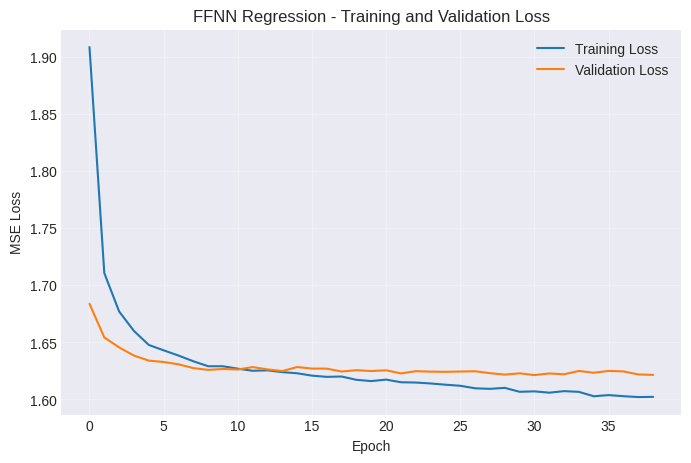

In [ ]:
#Plot loss
plt.figure(figsize=(8,5))

plt.plot(
    history_reg.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_reg.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('FFNN Regression - Training and Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

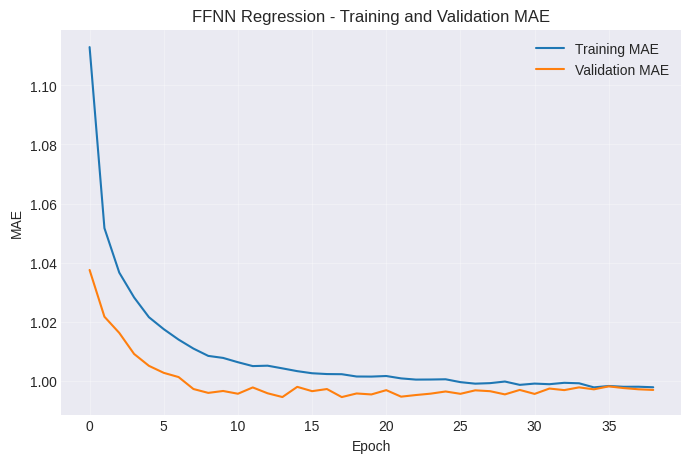

In [ ]:
#Plot MAE
plt.figure(figsize=(8,5))

plt.plot(
    history_reg.history['mae'],
    label='Training MAE'
)

plt.plot(
    history_reg.history['val_mae'],
    label='Validation MAE'
)

plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('FFNN Regression - Training and Validation MAE')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## 13.3. Model Validation

In [ ]:
# VALIDATION PREDICTIONS (REGRESSION MODEL)
# ============================================================
y_val_pred_reg = model_reg.predict(
    X_val_scaled,
    verbose=0
)

# Đưa kết quả dự đoán về dạng mảng 1 chiều
y_val_pred_reg = y_val_pred_reg.flatten()

print("Kích thước nhãn thực tế:", y_val.shape)
print("Kích thước nhãn dự đoán:", y_val_pred_reg.shape)
print("5 giá trị dự đoán đầu tiên:", y_val_pred_reg[:5])

Kích thước nhãn thực tế: (27078,)
Kích thước nhãn dự đoán: (27078,)
5 giá trị dự đoán đầu tiên: [ 1.781136   -0.09478129  1.8882746  -0.06826528  0.26142502]


In [ ]:
import numpy as np

print("=== TRAINING HISTORY ===")
print("Training loss:", history_reg.history["loss"])
print("Validation loss:", history_reg.history["val_loss"])

print("\n=== CHECK INPUT DATA ===")

for name in [
    "X_train", "X_train_scaled", "X_train_encoded",
    "X_val", "X_val_scaled", "X_val_encoded",
    "y_train", "y_val"
]:
    if name in globals():
        try:
            arr = np.asarray(globals()[name], dtype=float)
            print(
                name,
                "| Shape:", arr.shape,
                "| NaN:", np.isnan(arr).sum(),
                "| Inf:", np.isinf(arr).sum()
            )
        except (ValueError, TypeError):
            print(name, "| Contains non-numeric values")

=== TRAINING HISTORY ===
Training loss: [1.9084532260894775, 1.7106242179870605, 1.6770137548446655, 1.6599830389022827, 1.6477330923080444, 1.6430246829986572, 1.6384607553482056, 1.6334632635116577, 1.6291149854660034, 1.629093885421753, 1.6269642114639282, 1.6251285076141357, 1.6255048513412476, 1.6239262819290161, 1.6229521036148071, 1.620879054069519, 1.619803547859192, 1.620105504989624, 1.61720871925354, 1.6161017417907715, 1.6174060106277466, 1.6150777339935303, 1.614837408065796, 1.6140161752700806, 1.612945795059204, 1.6119967699050903, 1.6097981929779053, 1.6093130111694336, 1.6101717948913574, 1.6067442893981934, 1.607120156288147, 1.6059651374816895, 1.607305884361267, 1.60666823387146, 1.6028172969818115, 1.6038320064544678, 1.6028903722763062, 1.6021037101745605, 1.6023099422454834]
Validation loss: [1.6837679147720337, 1.6543279886245728, 1.6455527544021606, 1.638413906097412, 1.634016513824463, 1.6328282356262207, 1.6307820081710815, 1.6274845600128174, 1.6259022951126

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_regression_performance(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    metrics_df = pd.DataFrame({
        'Metric': ['Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)', 'Mean Absolute Error (MAE)', 'R-squared (R2)'],
        'Value': [mse, rmse, mae, r2]
    }).set_index('Metric')

    return metrics_df

# Tiến hành đánh giá hiệu năng mô hình hồi quy trên tập Validation
reg_performance_df = evaluate_regression_performance(y_val, y_val_pred_reg)

In [ ]:
# FINAL VALIDATION PERFORMANCE (REGRESSION MODEL)
# ============================================================

print("===== OVERALL REGRESSION PERFORMANCE ON VALIDATION SET =====")
display(
    reg_performance_df.round(4)
)

===== OVERALL REGRESSION PERFORMANCE ON VALIDATION SET =====


,Value
Metric,
Mean Squared Error (MSE),1.6075
Root Mean Squared Error (RMSE),1.2679
Mean Absolute Error (MAE),0.9956
R-squared (R2),0.2748


# 15. Testing

## 15.1. Test Prediction

In [ ]:
# TEST PREDICTIONS (REGRESSION MODEL)
# ============================================================

y_test_pred_reg = model_reg.predict(
    X_test_scaled,
    verbose=0
)

# Đưa kết quả dự đoán về dạng mảng 1 chiều
y_test_pred_reg = y_test_pred_reg.flatten()

print("Kích thước nhãn thực tế tập Test:", y_test.shape)
print("Kích thước nhãn dự đoán tập Test:", y_test_pred_reg.shape)
print("5 giá trị dự đoán tập Test đầu tiên:", y_test_pred_reg[:5])

Kích thước nhãn thực tế tập Test: (27078,)
Kích thước nhãn dự đoán tập Test: (27078,)
5 giá trị dự đoán tập Test đầu tiên: [-0.18046728 -0.09302575  2.0436573   0.4552928   0.03175447]


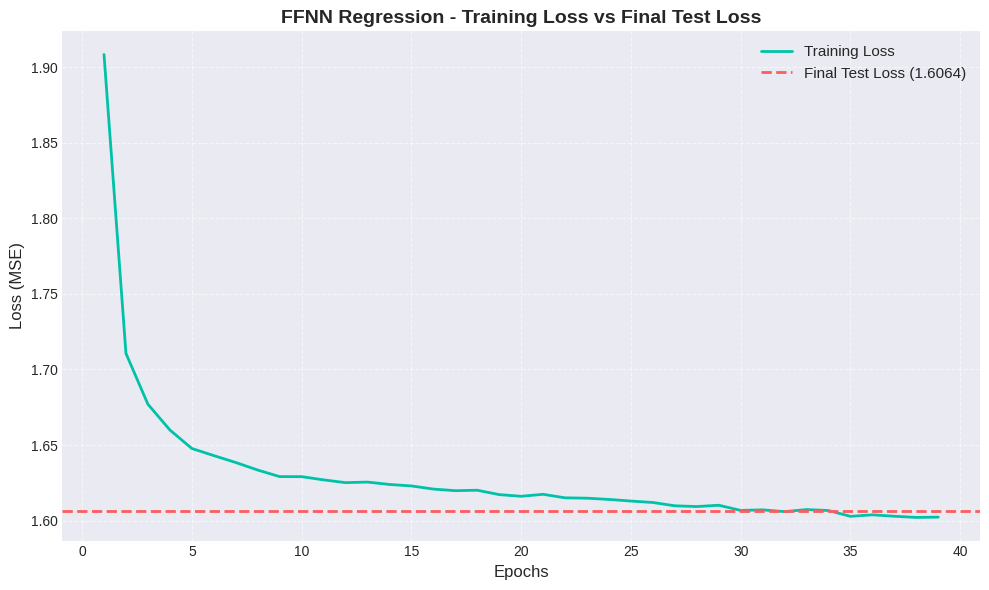

In [ ]:
import matplotlib.pyplot as plt

# Tính toán Test Loss thực tế từ tập dữ liệu Test
test_loss, test_mae = model_reg.evaluate(X_test_scaled, y_test, verbose=0)

plt.figure(figsize=(10, 6))
# Vẽ đường Training Loss qua các Epochs
epochs = range(1, len(history_reg.history['loss']) + 1)
plt.plot(epochs, history_reg.history['loss'], label='Training Loss', color='#00C2A8', linewidth=2)

# Đánh dấu điểm Test Loss cuối cùng trên biểu đồ
plt.axhline(y=test_loss, color='#FF5C5C', linestyle='--', linewidth=2,
            label=f'Final Test Loss ({test_loss:.4f})')

plt.title('FFNN Regression - Training Loss vs Final Test Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (MSE)', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## 15.2. Overall Test Metrics

In [ ]:
# EVALUATE REGRESSION PERFORMANCE ON TEST SET
# ============================================================

test_performance_df = evaluate_regression_performance(y_test, y_test_pred_reg)

print(" OVERALL REGRESSION PERFORMANCE ON TEST SET ")
display(
    test_performance_df.round(4)
)

 OVERALL REGRESSION PERFORMANCE ON TEST SET 


,Value
Metric,
Mean Squared Error (MSE),1.5926
Root Mean Squared Error (RMSE),1.2620
Mean Absolute Error (MAE),0.9908
R-squared (R2),0.2751


# 16. Model Persistence & Reproducibility

**Scope:** Save the existing single-output **Regression FFNN** from Section 13, without retraining or modifying it. The saved preprocessing schema belongs to the original row-level experiment (Sections 10–15), **not** to the later order-disjoint refits. Saving a model does not independently validate its generalization.

In [ ]:
# 16.1 — Persist the original Regression FFNN and its preprocessing
from pathlib import Path as persist_Path
import joblib as persist_joblib
import json as persist_json

persist_required = (
    'model_reg', 'scaler', 'oe', 'X_train_encoded',
    'ohe_cols', 'ord_cols', 'num_cols',
)
persist_missing = [name for name in persist_required if name not in globals()]
if persist_missing:
    raise RuntimeError(f'Sections 1–15 must run first: {persist_missing}')

persist_dir = persist_Path('/content/ffnn_regression_artifacts')
persist_dir.mkdir(parents=True, exist_ok=True)
model_reg.save(str(persist_dir / 'ffnn_regression_final.keras'))

persist_preprocessing = {
    'scaler': scaler,
    'ordinal_encoder': oe,
    'feature_columns': X_train_encoded.columns.tolist(),
    'onehot_columns': list(ohe_cols),
    'ordinal_columns': list(ord_cols),
    'numeric_columns': list(num_cols),
    'target': 'delay_duration',
}
persist_joblib.dump(
    persist_preprocessing,
    persist_dir / 'regression_preprocessing.pkl',
)
with (persist_dir / 'model_scope.json').open('w', encoding='utf-8') as file:
    persist_json.dump({
        'experiment': 'original row-level Regression FFNN',
        'model_variable': 'model_reg',
        'evaluated_in': 'Section 15; see Sections 19–24 for grouped/temporal checks',
        'order_disjoint_model': False,
    }, file, indent=2)
print('Saved original Regression FFNN artifacts to:', persist_dir)

Saved original Regression FFNN artifacts to: /content/ffnn_regression_artifacts


# 17. Research Limitations & Prediction-Time Assumptions

The **original Sections 1–15 are deliberately unchanged**. Their row-level random split excludes `Order Id` **as a predictor**, but that does *not* prevent items from the **same order** appearing in different splits. Section 19 audits this; Sections 21–22 provide the primary, order-disjoint evaluation. Interpret Section 15 as an **original diagnostic**, not a leakage-free estimate for novel orders.

**Target:** `delay_duration = Days for shipping (real) − Days for shipment (scheduled)` (days). The original data have item-level rows but an order-level delivery outcome. Distinguish an item-weighted MAE from an order-balanced MAE and state the estimand for every comparison.

**Prediction-time feature availability remains unverified.** Finance and fulfillment-related predictors (for example, fields containing `Profit`, `Sales`, or `shipping`) may or may not have been available at the intended prediction timestamp. The added audit flags these; it does **not** claim to prove absence of leakage. Feature selection informed by original whole-dataset EDA (Section 9) is also a design limitation that this add-on cannot retroactively remove.

**Interpretation policy:** No inference of causal impact from SHAP or permutation rankings. Bootstrap intervals below are **conditional on the fixed fitted models, split, and sampling assumptions**; training-seed variability and dependence between customers/orders/time require separate caution.

# 18. Evaluation Protocol — Read Before Robustness Tests

| Stage | Method | Role in the report |
|:--|:--|:--|
| Sections 10–15 | Original row-level split + Regression FFNN | Reproduce original pipeline; **diagnostic only** for new-order generalization |
| 19–20 | Split audit, train-only baseline fit | Quantify overlaps and establish fair comparisons |
| 21 | Order ID-disjoint grouped holdout, repeated training seeds | **Primary non-temporal held-out evaluation** |
| 22 | Chronological validation with label-time proxy purge | Temporal stress test; proxy time is not independently verified |
| 23 | Paired differences, subgroup and dependence diagnostics | Performance sensitivity; descriptive |
| 24 | Paired conditional bootstrap (order, customer, time-block sensitivity) | Sampling uncertainty under explicit clustering assumptions |
| 25 | Artifacts, manifests and integrity checks | Reproducibility |
| 26 | Permutation, SHAP, explanation-stability diagnostics | Non-causal model explanations on held-out orders |

**Important:** All extensions reuse the Section 13 `build_ffnn_stable()` **architecture and loss**, but fitted models in Sections 21–22/26 are *new fits* on their **own train-only preprocessing**; they are not the weights saved from the original Section 15 model. Comparisons use the same target and the same train/test partitions per experiment.

# 19. Validation & Robustness — Regression FFNN

**Primary objective:** Test whether the source FFNN architecture predicts unseen orders better than simple training-only baselines. This is an **extension**; it never overwrites the variables or weights from Sections 1–15. The Section 15 score remains a diagnostic of the original row-level split.

**Evaluation pathway:** 19 (audit) → 20 (baselines) → 21 (group holdout) → 22 (temporal) → 23 (paired differences and dependence) → 24 (clustered uncertainty) → 25 (exports) → 26 (explanations).


## 19.1. Experimental Configuration

All robustness refits call the original `build_ffnn_stable()` function. Model seeds are **training repetitions on a fixed split**, not repeated independent test datasets. They quantify training randomness, not sampling uncertainty.

In [ ]:
import gc as rv_gc
import hashlib as rv_hashlib
import importlib.metadata as rv_package_metadata
import json as rv_json
import platform as rv_platform
import random as rv_random
import sys as rv_sys
import time as rv_time
from pathlib import Path as rv_Path
import numpy as rv_np
import pandas as rv_pd
import matplotlib.pyplot as rv_plt
from sklearn.model_selection import GroupShuffleSplit as rv_GroupShuffleSplit
from sklearn.preprocessing import OrdinalEncoder as rv_OrdinalEncoder
from sklearn.preprocessing import StandardScaler as rv_StandardScaler

try:
    from IPython.display import display as rv_display
except ImportError:
    rv_display = print
try:
    import tensorflow as rv_tf
except ImportError:
    rv_tf = None

rv_RUN_GROUPED = True
rv_RUN_TEMPORAL = True
rv_GROUP_SEEDS = (42, 123, 2026, 7, 99)
rv_TEMPORAL_SEEDS = (42, 123, 2026)
rv_SPLIT_SEED = 42
rv_EPOCHS = 50
rv_BATCH_SIZE = 256
rv_PATIENCE = 8
rv_MIN_ORDERS = 50
rv_RUN_BOOTSTRAP = True
rv_BOOTSTRAP_BLOCK_DAYS = (7, 14)  # Sensitivity only; not independent replicates
rv_N_BOOTSTRAP = 2000
rv_BOOTSTRAP_SEED = 2026
rv_PRIMARY_COMPARATOR = 'ShippingModeMedian'
rv_BENCHMARKS = ('GlobalMean', 'GlobalMedian', 'ShippingModeMean', 'ShippingModeMedian')
rv_SAVE_PREDICTIONS = True
rv_OUT = (rv_Path('/content') if rv_Path('/content').exists() else rv_Path.cwd()) / 'ffnn_v4_regression_validation'
rv_OUT.mkdir(parents=True, exist_ok=True)

rv_required = ('df_raw', 'X', 'y', 'X_train', 'X_val', 'X_test', 'y_train',
               'y_val', 'y_test', 'y_test_pred_reg', 'ohe_cols', 'ord_cols', 'build_ffnn_stable')
rv_missing = [rv_name for rv_name in rv_required if rv_name not in globals()]
if rv_missing:
    raise RuntimeError(f'Missing original variables: {rv_missing}')
rv_OHE_COLUMNS = tuple(ohe_cols)
rv_ORDINAL_COLUMNS = tuple(ord_cols)


## 19.2. Input Alignment & Order ID Leakage Audit

`Order Id` is not passed to the FFNN, but it is retained here **only as a grouping and audit variable**. Any original train/test Order ID overlap is reported, not hidden or retroactively corrected.

In [ ]:
rv_X = X.copy(deep=True)
rv_y = y.copy(deep=True).astype(float)
assert rv_X.index.is_unique and df_raw.index.is_unique
assert rv_X.index.equals(rv_y.index)
assert rv_X.index.isin(df_raw.index).all()
rv_raw = df_raw.loc[rv_X.index]
rv_np.testing.assert_allclose(
    rv_y.to_numpy(),
    (rv_pd.to_numeric(rv_raw['Days for shipping (real)'])
     - rv_pd.to_numeric(rv_raw['Days for shipment (scheduled)'])).to_numpy())
assert rv_np.isfinite(rv_y.to_numpy()).all()
assert rv_raw['Order Id'].notna().all()

rv_meta = rv_pd.DataFrame({
    'order_id': rv_raw['Order Id'].astype(str),
    'order_time': rv_pd.to_datetime(rv_raw['order date (DateOrders)'], errors='coerce'),
    'label_time_proxy': rv_pd.to_datetime(rv_raw['shipping date (DateOrders)'], errors='coerce'),
    'shipping_mode': rv_X['Shipping Mode'].fillna('__MISSING__').astype(str),
    'y_days': rv_y,
}, index=rv_X.index)
if 'Order Status' in rv_raw:
    rv_meta['status'] = rv_raw['Order Status'].fillna('__MISSING__').astype(str).str.upper()
if 'Customer Id' in rv_raw:
    rv_meta['customer_id'] = rv_raw['Customer Id'].astype('string')
assert rv_meta['order_time'].notna().all()

rv_original_split = {'train': X_train.index.copy(), 'val': X_val.index.copy(),
                     'test': X_test.index.copy()}
for rv_part, rv_x_part, rv_y_part in (('train', X_train, y_train),
                                     ('val', X_val, y_val), ('test', X_test, y_test)):
    assert rv_x_part.index.equals(rv_y_part.index)
    rv_pd.testing.assert_frame_equal(rv_x_part, rv_X.loc[rv_x_part.index])
    rv_np.testing.assert_allclose(rv_y_part, rv_y.loc[rv_x_part.index])
assert sum(len(rv_ix) for rv_ix in rv_original_split.values()) == len(rv_X)
assert len(set().union(*(set(rv_ix) for rv_ix in rv_original_split.values()))) == len(rv_X)

rv_original_hashes = {
    rv_name: int(rv_pd.util.hash_pandas_object(globals()[rv_name], index=True).sum())
    for rv_name in ('X', 'y', 'X_train', 'X_val', 'X_test', 'y_train', 'y_val', 'y_test')
}
rv_original_model_hash = (rv_hashlib.sha256(b''.join(rv_w.tobytes() for rv_w in model_reg.get_weights())).hexdigest()
                          if 'model_reg' in globals() else None)

rv_audit_rows = []
for rv_a, rv_b in (('train', 'val'), ('train', 'test'), ('val', 'test')):
    rv_overlap_rows = set(rv_original_split[rv_a]) & set(rv_original_split[rv_b])
    rv_overlap_orders = (set(rv_meta.loc[rv_original_split[rv_a], 'order_id'])
                         & set(rv_meta.loc[rv_original_split[rv_b], 'order_id']))
    rv_audit_rows.extend([
        {'check': f'{rv_a}/{rv_b} row overlap', 'value': len(rv_overlap_rows),
         'status': 'FAIL' if rv_overlap_rows else 'PASS'},
        {'check': f'{rv_a}/{rv_b} order overlap', 'value': len(rv_overlap_orders),
         'status': 'FAIL' if rv_overlap_orders else 'PASS'},
    ])
rv_original_overlap = rv_meta.loc[rv_original_split['test'], 'order_id'].isin(
    rv_meta.loc[rv_original_split['train'], 'order_id'])
rv_audit_rows.append({'check': 'Test rows sharing train Order Id (%)',
                      'value': 100 * rv_original_overlap.mean(),
                      'status': 'FAIL' if rv_original_overlap.any() else 'PASS'})
if 'scaler' in globals() and 'X_train_ffnn' in globals():
    rv_scaler_match = (rv_np.allclose(scaler.mean_, rv_np.mean(X_train_ffnn, axis=0))
                       and rv_np.allclose(scaler.var_, rv_np.var(X_train_ffnn, axis=0)))
    rv_audit_rows.append({'check': 'Scaler statistics match train', 'value': bool(rv_scaler_match),
                          'status': 'PASS' if rv_scaler_match else 'FAIL'})
rv_audit = rv_pd.DataFrame(rv_audit_rows)
rv_order_consistency = rv_meta.groupby('order_id').agg(
    items=('y_days', 'size'), target_values=('y_days', 'nunique'),
    mode_values=('shipping_mode', 'nunique'), time_values=('order_time', 'nunique'))
rv_display(rv_audit)
rv_display(rv_order_consistency.describe().round(3))
rv_audit.to_csv(rv_OUT / '01_split_audit.csv', index=False)
rv_order_consistency.to_csv(rv_OUT / '01_order_consistency.csv')


,check,value,status
0,train/val row overlap,0,PASS
1,train/val order overlap,18290,FAIL
2,train/test row overlap,0,PASS
3,train/test order overlap,18457,FAIL
4,val/test row overlap,0,PASS
5,val/test order overlap,7213,FAIL
6,Test rows sharing train Order Id (%),83.174533,FAIL
7,Scaler statistics match train,True,PASS


,items,target_values,mode_values,time_values
count,65752.000,65752.0,65752.0,65752.0
mean,2.745,1.0,1.0,1.0
std,1.478,0.0,0.0,0.0
min,1.000,1.0,1.0,1.0
25%,1.000,1.0,1.0,1.0
50%,3.000,1.0,1.0,1.0
75%,4.000,1.0,1.0,1.0
max,5.000,1.0,1.0,1.0


# 20. Train-only Baselines & Comparable Regression Metrics

Global mean/median and Shipping-Mode mean/median are fitted **only on each experiment's training partition**. For each seed, all models are scored on the same test items/orders. `order_balanced` assigns each order equal aggregate weight; it is the primary robustness estimand.

In [ ]:
def rv_fit_benchmarks(train_index):
    rv_train = rv_meta.loc[train_index]
    return {'mean': float(rv_train['y_days'].mean()),
            'median': float(rv_train['y_days'].median()),
            'mode_stats': rv_train.groupby('shipping_mode')['y_days'].agg(['count', 'mean', 'median', 'std'])}

def rv_prediction_frame(row_index, fitted):
    rv_columns = [rv_c for rv_c in ('order_id', 'order_time', 'shipping_mode', 'y_days',
                                    'status', 'customer_id') if rv_c in rv_meta]
    rv_frame = rv_meta.loc[row_index, rv_columns].copy()
    rv_frame.index.name = 'row_id'
    rv_mode = rv_frame['shipping_mode']
    rv_frame['GlobalMean'] = fitted['mean']
    rv_frame['GlobalMedian'] = fitted['median']
    rv_frame['ShippingModeMean'] = rv_mode.map(fitted['mode_stats']['mean']).fillna(fitted['mean'])
    rv_frame['ShippingModeMedian'] = rv_mode.map(fitted['mode_stats']['median']).fillna(fitted['median'])
    return rv_frame

def rv_metric_table(frame, experiment, seed, ffnn_column):
    rv_true = frame['y_days'].to_numpy(dtype=float)
    rv_sizes = frame.groupby('order_id')['y_days'].transform('size').to_numpy(dtype=float)
    rv_rows = []
    for rv_weighting in ('item', 'order_balanced'):
        rv_weights = rv_np.ones(len(frame)) if rv_weighting == 'item' else 1.0 / rv_sizes
        rv_center = rv_np.average(rv_true, weights=rv_weights)
        rv_denominator = rv_np.sum(rv_weights * (rv_true - rv_center) ** 2)
        for rv_name, rv_column in (('FFNN_v3', ffnn_column), *[(rv_c, rv_c) for rv_c in rv_BENCHMARKS]):
            rv_pred = frame[rv_column].to_numpy(dtype=float)
            assert len(rv_pred) == len(rv_true) and rv_np.isfinite(rv_pred).all()
            rv_errors = rv_pred - rv_true
            rv_mse = rv_np.average(rv_errors ** 2, weights=rv_weights)
            rv_rows.append({'experiment': experiment, 'seed': seed, 'weighting': rv_weighting,
                            'model': rv_name, 'n_items': len(frame), 'n_orders': frame['order_id'].nunique(),
                            'MAE_days': rv_np.average(rv_np.abs(rv_errors), weights=rv_weights),
                            'MSE_days2': rv_mse, 'RMSE_days': rv_np.sqrt(rv_mse),
                            'R2': 1-rv_np.sum(rv_weights * rv_errors ** 2)/rv_denominator
                            if rv_denominator > 0 else rv_np.nan})
    return rv_pd.DataFrame(rv_rows)

rv_original_benchmarks = rv_fit_benchmarks(rv_original_split['train'])
rv_original_predictions = rv_prediction_frame(rv_original_split['test'], rv_original_benchmarks)
rv_existing_predictions = rv_np.asarray(y_test_pred_reg, dtype=float).reshape(-1).copy()
assert len(rv_existing_predictions) == len(rv_original_predictions)
rv_original_predictions['FFNN_original'] = rv_existing_predictions
rv_original_metrics = rv_metric_table(rv_original_predictions, 'original_diagnostic', 'original', 'FFNN_original')
rv_original_metrics['test_rows_share_train_order'] = bool(rv_original_overlap.any())
rv_display(rv_original_benchmarks['mode_stats'].round(5))
rv_display(rv_original_metrics.round(5))
rv_original_metrics.to_csv(rv_OUT / '02_original_diagnostic_metrics.csv', index=False)


,count,mean,median,std
shipping_mode,,,,
First Class,19498,1.00000,1.0,0.00000
Same Day,6769,0.47437,0.0,0.49938
Second Class,24719,1.99458,2.0,1.41889
Standard Class,75377,-0.00654,0.0,1.41745


,experiment,seed,weighting,model,n_items,n_orders,MAE_days,MSE_days2,RMSE_days,R2,test_rows_share_train_order
0,original_diagnostic,original,item,FFNN_v3,27078,22501,0.99083,1.59255,1.26196,0.27508,True
1,original_diagnostic,original,item,GlobalMean,27078,22501,1.19718,2.19687,1.48218,-0.00000,True
2,original_diagnostic,original,item,GlobalMedian,27078,22501,1.13313,2.38552,1.54451,-0.08587,True
3,original_diagnostic,original,item,ShippingModeMean,27078,22501,0.97672,1.59250,1.26194,0.27510,True
4,original_diagnostic,original,item,ShippingModeMedian,27078,22501,0.97470,1.60496,1.26687,0.26943,True
5,original_diagnostic,original,order_balanced,FFNN_v3,27078,22501,0.99387,1.59862,1.26436,0.27564,True
6,original_diagnostic,original,order_balanced,GlobalMean,27078,22501,1.20063,2.20695,1.48558,-0.00001,True
7,original_diagnostic,original,order_balanced,GlobalMedian,27078,22501,1.13511,2.39220,1.54668,-0.08395,True
8,original_diagnostic,original,order_balanced,ShippingModeMean,27078,22501,0.98000,1.59880,1.26444,0.27556,True
9,original_diagnostic,original,order_balanced,ShippingModeMedian,27078,22501,0.97800,1.61140,1.26941,0.26985,True


# 21. Grouped Holdout — Order-Disjoint Train/Validation/Test

Use `GroupShuffleSplit(groups=Order Id)` twice to create disjoint sets; fit every encoder/scaler on grouped **train only**. The original FFNN architecture is refitted for each training seed. An order-level outcome repeated on item-level rows is handled by reporting both item-weighted and order-balanced metrics.

In [ ]:
def rv_validate_split(split):
    assert set(split) == {'train', 'val', 'test'}
    for rv_a, rv_b in (('train', 'val'), ('train', 'test'), ('val', 'test')):
        assert not (set(split[rv_a]) & set(split[rv_b]))
        assert not (set(rv_meta.loc[split[rv_a], 'order_id']) & set(rv_meta.loc[split[rv_b], 'order_id']))
    for rv_part, rv_index in split.items():
        assert rv_meta.loc[rv_index, 'order_id'].nunique() >= rv_MIN_ORDERS, rv_part

def rv_group_split():
    rv_first = rv_GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=rv_SPLIT_SEED)
    rv_train_pos, rv_temp_pos = next(rv_first.split(rv_X, groups=rv_meta['order_id']))
    rv_temp_index = rv_X.index[rv_temp_pos]
    rv_second = rv_GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=rv_SPLIT_SEED)
    rv_val_pos, rv_test_pos = next(rv_second.split(rv_X.loc[rv_temp_index],
                                                  groups=rv_meta.loc[rv_temp_index, 'order_id']))
    rv_split = {'train': rv_X.index[rv_train_pos], 'val': rv_temp_index[rv_val_pos],
                'test': rv_temp_index[rv_test_pos]}
    rv_validate_split(rv_split)
    return rv_split

def rv_prepare_inputs(split):
    rv_validate_split(split)
    rv_frames = {rv_p: rv_X.loc[rv_ix].copy() for rv_p, rv_ix in split.items()}
    rv_numeric = [rv_c for rv_c in rv_X if rv_c not in rv_OHE_COLUMNS + rv_ORDINAL_COLUMNS]
    rv_onehot = {rv_p: rv_pd.get_dummies(rv_f[list(rv_OHE_COLUMNS)], drop_first=False)
                 for rv_p, rv_f in rv_frames.items()}
    rv_encoder = rv_OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    rv_ordinal = {'train': rv_encoder.fit_transform(rv_frames['train'][list(rv_ORDINAL_COLUMNS)])}
    rv_ordinal.update({rv_p: rv_encoder.transform(rv_frames[rv_p][list(rv_ORDINAL_COLUMNS)])
                       for rv_p in ('val', 'test')})
    rv_arrays = {}
    for rv_part, rv_frame in rv_frames.items():
        rv_encoded = rv_pd.concat([
            rv_frame[rv_numeric],
            rv_onehot[rv_part].reindex(columns=rv_onehot['train'].columns, fill_value=0),
            rv_pd.DataFrame(rv_ordinal[rv_part], columns=rv_ORDINAL_COLUMNS, index=rv_frame.index),
        ], axis=1)
        rv_arrays[rv_part] = rv_encoded.to_numpy(dtype=float)
        assert rv_np.isfinite(rv_arrays[rv_part]).all(), f'Nonfinite input: {rv_part}'
    rv_scaler_local = rv_StandardScaler()
    rv_arrays['train'] = rv_scaler_local.fit_transform(rv_arrays['train']).astype('float32')
    for rv_part in ('val', 'test'):
        rv_arrays[rv_part] = rv_scaler_local.transform(rv_arrays[rv_part]).astype('float32')
    return rv_arrays

def rv_train_predict(arrays, split, seed):
    if rv_tf is None:
        raise ImportError('TensorFlow is required for robustness training.')
    rv_np_state, rv_py_state = rv_np.random.get_state(), rv_random.getstate()
    rv_model = None
    try:
        rv_tf.keras.utils.set_random_seed(int(seed))
        rv_started = rv_time.perf_counter()
        rv_model = build_ffnn_stable(input_dim=arrays['train'].shape[1])
        assert rv_model.output_shape[-1] == 1
        rv_stopping = rv_tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=rv_PATIENCE, restore_best_weights=True, verbose=0)
        rv_history = rv_model.fit(arrays['train'], rv_y.loc[split['train']].to_numpy(dtype='float32'),
                                  validation_data=(arrays['val'], rv_y.loc[split['val']].to_numpy(dtype='float32')),
                                  epochs=rv_EPOCHS, batch_size=rv_BATCH_SIZE,
                                  callbacks=[rv_stopping], shuffle=True, verbose=0)
        rv_prediction = rv_model.predict(arrays['test'], verbose=0).reshape(-1)
        rv_info = {'epochs': len(rv_history.history['loss']),
                   'best_epoch': int(rv_np.argmin(rv_history.history['val_loss'])) + 1,
                   'seconds': rv_time.perf_counter() - rv_started}
        return rv_prediction, rv_info, rv_history.history
    finally:
        rv_np.random.set_state(rv_np_state)
        rv_random.setstate(rv_py_state)
        del rv_model
        rv_gc.collect()

def rv_run_experiment(split, name, seeds):
    rv_arrays = rv_prepare_inputs(split)
    rv_fitted = rv_fit_benchmarks(split['train'])
    rv_predictions = rv_prediction_frame(split['test'], rv_fitted)
    rv_tables, rv_training = [], []
    rv_fitted['mode_stats'].to_csv(rv_OUT / f'{name}_train_mode_statistics.csv')
    rv_pd.concat([rv_pd.DataFrame({'row_id': rv_ix, 'part': rv_part})
                  for rv_part, rv_ix in split.items()], ignore_index=True).to_csv(
                      rv_OUT / f'{name}_split_rows.csv', index=False)
    for rv_seed in seeds:
        print(f'{name} | seed={rv_seed}', flush=True)
        rv_pred, rv_info, rv_history = rv_train_predict(rv_arrays, split, rv_seed)
        rv_column = f'FFNN_seed_{rv_seed}'
        assert len(rv_pred) == len(rv_predictions) and rv_np.isfinite(rv_pred).all()
        rv_predictions[rv_column] = rv_pred
        rv_tables.append(rv_metric_table(rv_predictions, name, rv_seed, rv_column))
        rv_training.append({'experiment': name, 'seed': rv_seed, **rv_info})
        rv_pd.DataFrame(rv_history).to_csv(rv_OUT / f'{name}_seed_{rv_seed}_history.csv', index=False)
        rv_pd.concat(rv_tables, ignore_index=True).to_csv(rv_OUT / f'{name}_metrics.csv', index=False)
        if rv_SAVE_PREDICTIONS:
            rv_predictions.to_csv(rv_OUT / f'{name}_predictions.csv')
    return {'experiment': name, 'split': split, 'seeds': tuple(seeds), 'predictions': rv_predictions,
            'metrics': rv_pd.concat(rv_tables, ignore_index=True), 'training': rv_pd.DataFrame(rv_training)}


In [ ]:
rv_results = {}
if rv_RUN_GROUPED:
    rv_grouped_split = rv_group_split()
    rv_grouped_sizes = rv_pd.DataFrame([
        {'part': rv_p, 'items': len(rv_ix), 'orders': rv_meta.loc[rv_ix, 'order_id'].nunique()}
        for rv_p, rv_ix in rv_grouped_split.items()])
    rv_display(rv_grouped_sizes)
    rv_results['grouped'] = rv_run_experiment(rv_grouped_split, 'grouped', rv_GROUP_SEEDS)
    rv_display(rv_results['grouped']['metrics'].groupby(['weighting', 'model'])[
        ['MAE_days', 'MSE_days2', 'RMSE_days', 'R2']].agg(['mean', 'std']).round(5))


,part,items,orders
0,train,126088,46026
1,val,27132,9863
2,test,27299,9863


grouped | seed=42


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


grouped | seed=123


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


grouped | seed=2026


... (2 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


grouped | seed=99


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


MAE_days          MSE_days2           \
                                      mean      std      mean      std   
weighting      model                                                     
item           FFNN_v3             1.00297  0.00112   1.61801  0.00176   
               GlobalMean          1.19881  0.00000   2.20603  0.00000   
               GlobalMedian        1.14048  0.00000   2.41650  0.00000   
               ShippingModeMean    0.98296  0.00000   1.60572  0.00000   
               ShippingModeMedian  0.98135  0.00000   1.61771  0.00000   
order_balanced FFNN_v3             1.00345  0.00146   1.61752  0.00297   
               GlobalMean          1.19888  0.00000   2.20921  0.00000   
               GlobalMedian        1.13921  0.00000   2.41063  0.00000   
               ShippingModeMean    0.98199  0.00000   1.60360  0.00000   
               ShippingModeMedian  0.98094  0.00000   1.61645  0.00000   

                                  RMSE_days                R2           
                                       mean      std     mean      std  
weighting      model                                                    
item           FFNN_v3              1.27201  0.00069  0.26628  0.00080  
               GlobalMean           1.48527  0.00000 -0.00037  0.00000  
               GlobalMedian         1.55451  0.00000 -0.09581  0.00000  
               ShippingModeMean     1.26717  0.00000  0.27185  0.00000  
               ShippingModeMedian   1.27189  0.00000  0.26642  0.00000  
order_balanced FFNN_v3              1.27182  0.00117  0.26772  0.00134  
               GlobalMean           1.48634  0.00000 -0.00015  0.00000  
               GlobalMedian         1.55262  0.00000 -0.09133  0.00000  
               ShippingModeMean     1.26633  0.00000  0.27402  0.00000  
               ShippingModeMedian   1.27140  0.00000  0.26821  0.00000

# 22. Temporal Validation — Chronological Windows & Label-Proxy Purge

Train/validation/test windows are ordered in **order placement time** with disjoint Order IDs within each experiment. Train and validation are purged using the source `shipping date (DateOrders)` field as a **label-availability proxy**, not a validated ground-truth event timestamp. Windows are not independent replications; training periods overlap by design.

In [ ]:
def rv_make_temporal_windows():
    assert rv_meta['label_time_proxy'].notna().all()
    assert (rv_meta['label_time_proxy'] >= rv_meta['order_time']).all()
    assert rv_meta.groupby('order_id')['order_time'].nunique().eq(1).all()
    rv_orders = rv_meta.groupby('order_id').agg(order_time=('order_time', 'min'),
                                                label_time=('label_time_proxy', 'max'))
    rv_days = rv_pd.DatetimeIndex(rv_orders['order_time'].dt.normalize().unique()).sort_values()
    assert len(rv_days) >= 20
    rv_windows, rv_dates, rv_previous_tests = [], [], set()
    for rv_i, rv_fractions in enumerate(((.40, .55, .70), (.55, .70, .85), (.70, .85, 1.)), start=1):
        rv_cut1 = rv_days[int(len(rv_days) * rv_fractions[0])]
        rv_cut2 = rv_days[int(len(rv_days) * rv_fractions[1])]
        rv_cut3 = (rv_days[int(len(rv_days) * rv_fractions[2])] if rv_fractions[2] < 1
                   else rv_days[-1] + rv_pd.Timedelta(days=1))
        rv_train_candidate = rv_orders['order_time'].lt(rv_cut1)
        rv_val_candidate = rv_orders['order_time'].ge(rv_cut1) & rv_orders['order_time'].lt(rv_cut2)
        rv_masks = {'train': rv_train_candidate & rv_orders['label_time'].lt(rv_cut1),
                    'val': rv_val_candidate & rv_orders['label_time'].lt(rv_cut2),
                    'test': rv_orders['order_time'].ge(rv_cut2) & rv_orders['order_time'].lt(rv_cut3)}
        rv_split = {rv_p: rv_meta.index[rv_meta['order_id'].isin(rv_orders.index[rv_mask])]
                    for rv_p, rv_mask in rv_masks.items()}
        rv_validate_split(rv_split)
        assert rv_meta.loc[rv_split['train'], 'label_time_proxy'].max() < rv_cut1
        assert rv_meta.loc[rv_split['val'], 'label_time_proxy'].max() < rv_cut2
        rv_test_orders = set(rv_meta.loc[rv_split['test'], 'order_id'])
        assert not rv_previous_tests & rv_test_orders
        rv_previous_tests.update(rv_test_orders)
        rv_name = f'temporal_{rv_i}'
        rv_windows.append((rv_name, rv_split))
        rv_record = {'experiment': rv_name, 'train_before': str(rv_cut1),
                     'test_start': str(rv_cut2), 'test_before': str(rv_cut3),
                     'purged_train_orders': int((rv_train_candidate & ~rv_masks['train']).sum()),
                     'purged_val_orders': int((rv_val_candidate & ~rv_masks['val']).sum())}
        for rv_part, rv_ix in rv_split.items():
            rv_record[f'{rv_part}_items'] = len(rv_ix)
            rv_record[f'{rv_part}_orders'] = rv_meta.loc[rv_ix, 'order_id'].nunique()
        rv_dates.append(rv_record)
    return rv_windows, rv_pd.DataFrame(rv_dates)

if rv_RUN_TEMPORAL:
    rv_windows, rv_temporal_dates = rv_make_temporal_windows()
    rv_display(rv_temporal_dates)
    rv_temporal_dates.to_csv(rv_OUT / '03_temporal_windows.csv', index=False)
    for rv_window_name, rv_window_split in rv_windows:
        rv_results[rv_window_name] = rv_run_experiment(rv_window_split, rv_window_name, rv_TEMPORAL_SEEDS)


,experiment,train_before,test_start,test_before,purged_train_orders,purged_val_orders,train_items,train_orders,val_items,val_orders,test_items,test_orders
0,temporal_1,2016-03-26 00:00:00,2016-09-11 00:00:00,2017-02-27 00:00:00,209,207,76431,25538,28251,9396,29106,9656
1,temporal_2,2016-09-11 00:00:00,2017-02-27 00:00:00,2017-08-15 00:00:00,207,203,105285,35143,28493,9453,28876,9647
2,temporal_3,2017-02-27 00:00:00,2017-08-15 00:00:00,2018-02-01 00:00:00,203,174,134361,44803,28337,9473,16669,11099


temporal_1 | seed=42


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


temporal_1 | seed=123


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


temporal_1 | seed=2026


... (9 outputs left out)

temporal_3 | seed=123


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


temporal_3 | seed=2026


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# 23. Sensitivity Analysis — Paired Metrics, Subgroups & Dependence

Positive `FFNN − ShippingModeMedian` **MAE** means the FFNN is *worse* on that split. Comparing averaged training-seed metrics is descriptive; do not present SD across training seeds as a confidence interval for new orders. Subgroup metrics can be unstable for small groups. Examine repeated-customer and daily dependence before interpreting Section 24.

MAE_days           \
                                                          mean      std   
experiment          weighting      model                                  
grouped             item           FFNN_v3             1.00297  0.00112   
                                   GlobalMean          1.19881  0.00000   
                                   GlobalMedian        1.14048  0.00000   
                                   ShippingModeMean    0.98296  0.00000   
                                   ShippingModeMedian  0.98135  0.00000   
                    order_balanced FFNN_v3             1.00345  0.00146   
                                   GlobalMean          1.19888  0.00000   
                                   GlobalMedian        1.13921  0.00000   
                                   ShippingModeMean    0.98199  0.00000   
                                   ShippingModeMedian  0.98094  0.00000   
original_diagnostic item           FFNN_v3             0.99083      NaN   
                                   GlobalMean          1.19718      NaN   
                                   GlobalMedian        1.13313      NaN   
                                   ShippingModeMean    0.97672      NaN   
                                   ShippingModeMedian  0.97470      NaN   
                    order_balanced FFNN_v3             0.99387      NaN   
                                   GlobalMean          1.20063      NaN   
                                   GlobalMedian        1.13511      NaN   
                                   ShippingModeMean    0.98000      NaN   
                                   ShippingModeMedian  0.97800      NaN   
temporal_1          item           FFNN_v3             1.01367  0.00121   
                                   GlobalMean          1.20043  0.00000   
                                   GlobalMedian        1.13791  0.00000   
                                   ShippingModeMean    0.97983  0.00000   
                                   ShippingModeMedian  0.97647  0.00000   
                    order_balanced FFNN_v3             1.01608  0.00101   
                                   GlobalMean          1.20156  0.00000   
                                   GlobalMedian        1.13826  0.00000   
                                   ShippingModeMean    0.98185  0.00000   
                                   ShippingModeMedian  0.97867  0.00000   
temporal_2          item           FFNN_v3             1.00114  0.00322   
                                   GlobalMean          1.19268  0.00000   
                                   GlobalMedian        1.13201  0.00000   
                                   ShippingModeMean    0.97270  0.00000   
                                   ShippingModeMedian  0.97133  0.00000   
                    order_balanced FFNN_v3             1.00064  0.00346   
                                   GlobalMean          1.19832  0.00000   
                                   GlobalMedian        1.13683  0.00000   
                                   ShippingModeMean    0.97174  0.00000   
                                   ShippingModeMedian  0.97108  0.00000   
temporal_3          item           FFNN_v3             1.01232  0.00344   
                                   GlobalMean          1.20881  0.00000   
                                   GlobalMedian        1.13852  0.00000   
                                   ShippingModeMean    0.98316  0.00000   
                                   ShippingModeMedian  0.98578  0.00000   
                    order_balanced FFNN_v3             1.01503  0.00419   
                                   GlobalMean          1.20782  0.00000   
                                   GlobalMedian        1.13947  0.00000   
                                   ShippingModeMean    0.98222  0.00000   
                                   ShippingModeMedian  0.98324  0.00000   

                                                      MSE_days2           \
  

,experiment,seed,weighting,comparator,delta_MAE_days,delta_MSE_days2,delta_RMSE_days,delta_R2
4,original_diagnostic,original,order_balanced,GlobalMean,-0.206760,-0.608337,-0.221218,0.275647
5,original_diagnostic,original,order_balanced,GlobalMedian,-0.141236,-0.793590,-0.282312,0.359588
6,original_diagnostic,original,order_balanced,ShippingModeMean,0.013872,-0.000187,-0.000074,0.000085
7,original_diagnostic,original,order_balanced,ShippingModeMedian,0.015868,-0.012780,-0.005044,0.005791
12,grouped,42,order_balanced,GlobalMean,-0.195402,-0.591501,-0.214449,0.267782
13,grouped,42,order_balanced,GlobalMedian,-0.135730,-0.792916,-0.280727,0.358966
14,grouped,42,order_balanced,ShippingModeMean,0.021488,0.014107,0.005558,-0.006386
15,grouped,42,order_balanced,ShippingModeMedian,0.022538,0.001264,0.000497,-0.000572
20,grouped,123,order_balanced,GlobalMean,-0.194895,-0.593993,-0.215429,0.268911
21,grouped,123,order_balanced,GlobalMedian,-0.135223,-0.795408,-0.281707,0.360095


,experiment,seed,weighting,model,n_items,n_orders,MAE_days,MSE_days2,RMSE_days,R2,shipping_mode
5,grouped,42,order_balanced,FFNN_v3,4205,1492,0.05533,0.00605,0.07775,NaN,First Class
6,grouped,42,order_balanced,GlobalMean,4205,1492,0.43117,0.18591,0.43117,NaN,First Class
7,grouped,42,order_balanced,GlobalMedian,4205,1492,0.00000,0.00000,0.00000,NaN,First Class
8,grouped,42,order_balanced,ShippingModeMean,4205,1492,0.00000,0.00000,0.00000,NaN,First Class
9,grouped,42,order_balanced,ShippingModeMedian,4205,1492,0.00000,0.00000,0.00000,NaN,First Class
...,...,...,...,...,...,...,...,...,...,...,...
555,temporal_3,2026,order_balanced,FFNN_v3,9839,6597,1.22423,2.03060,1.42499,-0.00881,Standard Class
556,temporal_3,2026,order_balanced,GlobalMean,9839,6597,1.31831,2.33659,1.52859,-0.16083,Standard Class
557,temporal_3,2026,order_balanced,GlobalMedian,9839,6597,1.40609,3.02228,1.73847,-0.50148,Standard Class
558,temporal_3,2026,order_balanced,ShippingModeMean,9839,6597,1.20572,2.01286,1.41875,-0.00000,Standard Class


,experiment,test_orders,test_days,customers_with_repeated_test_orders,daily_loss_lag1_correlation
0,grouped,9863,1127,1902,0.05345
1,temporal_1,9656,169,2262,-0.11202
2,temporal_2,9647,169,2264,-0.11534
3,temporal_3,11099,170,265,0.33930


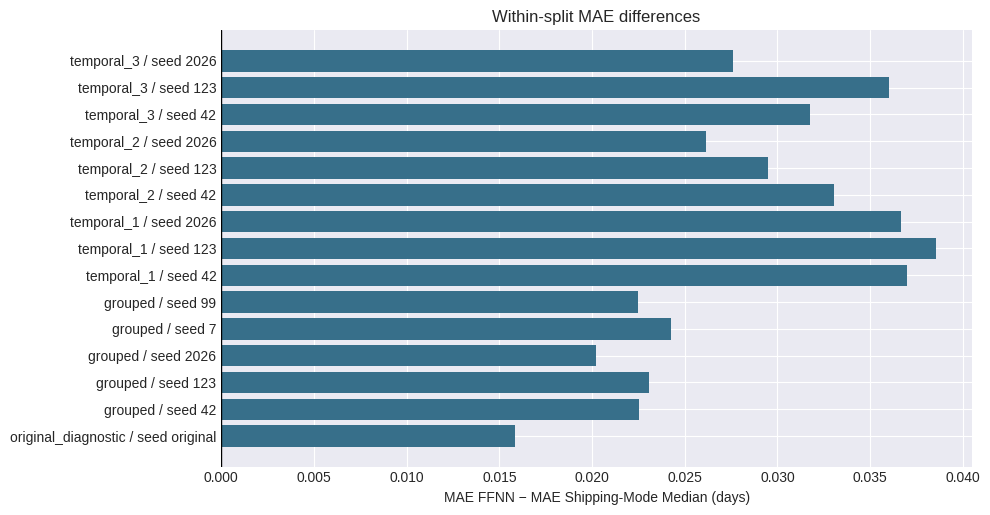

model,experiment,FFNN_v3,ShippingModeMedian,delta_MAE_FFNN_minus_baseline_days
0,grouped,1.00345,0.98094,0.02251
1,temporal_1,1.01608,0.97867,0.03741
2,temporal_2,1.00064,0.97108,0.02956
3,temporal_3,1.01503,0.98324,0.03179


,predictor,requires_prediction_time_verification,verified_available_at_prediction_time,note
6,Order Item Discount,True,False,Availability unknown from the source dataset; ...
7,Order Item Discount Rate,True,False,Availability unknown from the source dataset; ...
9,Order Item Profit Ratio,True,False,Availability unknown from the source dataset; ...
11,Sales,True,False,Availability unknown from the source dataset; ...
12,Order Profit Per Order,True,False,Availability unknown from the source dataset; ...
16,Shipping Mode,True,False,Availability unknown from the source dataset; ...


Caution: feature timing and train-only feature selection remain unverified in Sections 1–15.


In [ ]:
rv_all_metrics = rv_pd.concat([rv_original_metrics, *[rv_r['metrics'] for rv_r in rv_results.values()]],
                              ignore_index=True)
rv_seed_summary = rv_all_metrics.groupby(['experiment', 'weighting', 'model'])[
    ['MAE_days', 'MSE_days2', 'RMSE_days', 'R2']].agg(['mean', 'std'])
rv_display(rv_seed_summary.round(5))
rv_keys = ['experiment', 'seed', 'weighting']
rv_ffnn_metrics = rv_all_metrics.loc[rv_all_metrics['model'].eq('FFNN_v3')]
rv_benchmark_metrics = rv_all_metrics.loc[~rv_all_metrics['model'].eq('FFNN_v3')]
rv_paired = rv_ffnn_metrics.merge(rv_benchmark_metrics, on=rv_keys,
                                 suffixes=('_ffnn', '_benchmark'), validate='one_to_many')
rv_differences = rv_paired[rv_keys + ['model_benchmark']].rename(
    columns={'model_benchmark': 'comparator'}).copy()
for rv_metric in ('MAE_days', 'MSE_days2', 'RMSE_days', 'R2'):
    rv_differences[f'delta_{rv_metric}'] = rv_paired[f'{rv_metric}_ffnn'] - rv_paired[f'{rv_metric}_benchmark']
rv_display(rv_differences.query("weighting == 'order_balanced'").round(6))

rv_subgroup_tables, rv_dependence_rows = [], []
for rv_name, rv_result in rv_results.items():
    rv_frame = rv_result['predictions']
    for rv_mode, rv_subset in rv_frame.groupby('shipping_mode'):
        for rv_seed in rv_result['seeds']:
            rv_table = rv_metric_table(rv_subset, rv_name, rv_seed, f'FFNN_seed_{rv_seed}')
            rv_table['shipping_mode'] = rv_mode
            rv_subgroup_tables.append(rv_table)
    rv_item_loss = rv_np.column_stack([
        rv_np.abs(rv_frame[f'FFNN_seed_{rv_s}'] - rv_frame['y_days']) for rv_s in rv_result['seeds']]).mean(axis=1)
    rv_loss_frame = rv_frame[['order_id', 'order_time']].copy()
    rv_loss_frame['loss_difference_days'] = rv_item_loss - rv_np.abs(
        rv_frame[rv_PRIMARY_COMPARATOR] - rv_frame['y_days'])
    rv_order_loss = rv_loss_frame.groupby('order_id').agg(
        order_time=('order_time', 'min'), loss_difference_days=('loss_difference_days', 'mean'))
    rv_daily = rv_order_loss.groupby(rv_order_loss['order_time'].dt.normalize())['loss_difference_days'].agg(['size', 'mean'])
    rv_daily.to_csv(rv_OUT / f'{rv_name}_daily_loss_differences.csv')
    rv_dependence_rows.append({'experiment': rv_name, 'test_orders': rv_frame['order_id'].nunique(),
                               'test_days': len(rv_daily),
                               'customers_with_repeated_test_orders': int(rv_frame.groupby('customer_id')['order_id'].nunique().gt(1).sum())
                               if 'customer_id' in rv_frame else rv_np.nan,
                               'daily_loss_lag1_correlation': rv_daily['mean'].autocorr(1) if len(rv_daily) > 2 else rv_np.nan})
rv_subgroup_metrics = rv_pd.concat(rv_subgroup_tables, ignore_index=True) if rv_subgroup_tables else rv_pd.DataFrame()
rv_dependence = rv_pd.DataFrame(rv_dependence_rows)
if not rv_subgroup_metrics.empty:
    rv_display(rv_subgroup_metrics.query("weighting == 'order_balanced'").round(5))
if not rv_dependence.empty:
    rv_display(rv_dependence.round(5))

rv_plot = rv_differences.query("weighting == 'order_balanced' and comparator == @rv_PRIMARY_COMPARATOR").copy()
rv_plot['label'] = rv_plot['experiment'] + ' / seed ' + rv_plot['seed'].astype(str)
rv_figure, rv_axis = rv_plt.subplots(figsize=(10, max(3, 0.35 * len(rv_plot))))
rv_axis.barh(rv_plot['label'], rv_plot['delta_MAE_days'], color='#376f8a')
rv_axis.axvline(0, color='black', linewidth=1)
rv_axis.set(xlabel='MAE FFNN − MAE Shipping-Mode Median (days)', title='Within-split MAE differences')
rv_figure.tight_layout()
rv_figure.savefig(rv_OUT / '04_MAE_differences.png', dpi=180)
rv_plt.show()


# 23.1 — Decision-facing performance summary (no model-selection claim)
rv_primary_rows = rv_all_metrics.loc[
    rv_all_metrics['experiment'].ne('original_diagnostic')
    & rv_all_metrics['weighting'].eq('order_balanced')
    & rv_all_metrics['model'].isin(('FFNN_v3', rv_PRIMARY_COMPARATOR))
].copy()
rv_primary_summary = (rv_primary_rows.groupby(['experiment', 'model'], as_index=False)
                      .agg(mean_MAE_days=('MAE_days', 'mean'),
                           sd_training_seeds_MAE_days=('MAE_days', 'std'),
                           n_training_seed_rows=('MAE_days', 'size')))
rv_primary_wide = rv_primary_summary.pivot(
    index='experiment', columns='model', values='mean_MAE_days').reset_index()
rv_primary_wide['delta_MAE_FFNN_minus_baseline_days'] = (
    rv_primary_wide['FFNN_v3'] - rv_primary_wide[rv_PRIMARY_COMPARATOR]
)
rv_display(rv_primary_wide.round(5))
rv_primary_wide.to_csv(rv_OUT / '04_primary_performance_comparison.csv', index=False)

# Feature-availability warning is a research-design audit, NOT a proof of leakage.
rv_feature_timing_flags = rv_pd.DataFrame([
    {'predictor': col,
     'requires_prediction_time_verification': bool(
         any(token in col.lower() for token in
             ('profit', 'sales', 'discount', 'shipping', 'order status', 'delivery'))),
     'verified_available_at_prediction_time': False,
     'note': 'Availability unknown from the source dataset; obtain data provenance.'}
    for col in rv_X.columns
])
rv_feature_timing_flags.to_csv(rv_OUT / '04_feature_availability_audit.csv', index=False)
rv_display(rv_feature_timing_flags.loc[
    rv_feature_timing_flags['requires_prediction_time_verification']])
print('Caution: feature timing and train-only feature selection remain unverified in Sections 1–15.')


# 24. Statistical Uncertainty — Conditional Paired Cluster Bootstrap

**Method:** For each held-out order, average the FFNN absolute loss **over trained seeds first** and compare it to the training-fitted Shipping-Mode Median on the *same observed items*. Average item losses within each Order ID. The order-balanced mean loss difference is the estimand in Section 23.

- **Order-cluster bootstrap:** Samples orders with replacement; assumes approximately exchangeable/independent orders. This is a *conditional diagnostic*, not proof of independence.
- **Customer-cluster sensitivity:** Samples customers (repeated orders remain together); assumes customers are suitable resampling units. Where customer IDs are missing, the method is skipped rather than silently assuming independence.
- **Time-block sensitivity:** Moving-block bootstrap on daily order-loss aggregates (7/14 days, subject to window length), to probe serial dependence; assumes approximate stationarity within the assessment window. It is not a substitute for an out-of-time test.

Report 95% percentile intervals **conditional on these assumptions, the fixed fitted seed models and the observed split**. These are **not** confidence intervals for model retraining variability and do not establish causality. No effect is declared significant merely because a code cell executes.

In [ ]:
# 24.1 — Paired, order-balanced differences on fixed trained-seed models
def rv_order_loss_differences(result):
    rv_validate_split(result['split'])
    frame = result['predictions']
    truth = frame['y_days'].to_numpy(dtype=float)
    baseline = frame[rv_PRIMARY_COMPARATOR].to_numpy(dtype=float)
    assert rv_np.isfinite(truth).all() and rv_np.isfinite(baseline).all()
    seed_columns = [f'FFNN_seed_{seed}' for seed in result['seeds']]
    assert all(col in frame.columns for col in seed_columns)
    seed_predictions = frame[seed_columns].to_numpy(dtype=float)
    assert rv_np.isfinite(seed_predictions).all()
    # The mean of per-seed absolute losses preserves the Section 23 estimand.
    loss_ffnn = rv_np.abs(seed_predictions - truth[:, None]).mean(axis=1)
    loss_baseline = rv_np.abs(baseline - truth)
    item = rv_pd.DataFrame({
        'order_id': frame['order_id'].to_numpy(),
        'order_time': rv_pd.to_datetime(frame['order_time']).to_numpy(),
        'delta': loss_ffnn - loss_baseline,
    }, index=frame.index)
    if 'customer_id' in frame:
        item['customer_id'] = frame['customer_id'].to_numpy()
    agg = {'delta': 'mean', 'order_time': 'min'}
    if 'customer_id' in item:
        agg['customer_id'] = 'first'
    orders = item.groupby('order_id', sort=False).agg(agg).reset_index()
    if 'customer_id' in item:
        rv_nunique = item.groupby('order_id')['customer_id'].nunique(dropna=True)
        assert (rv_nunique <= 1).all(), 'Customer ID differs within the same order.'
    assert len(orders) >= rv_MIN_ORDERS
    assert rv_np.isfinite(orders['delta']).all()
    return orders


def rv_bootstrap_order(orders, rng, n_boot):
    differences = orders['delta'].to_numpy(dtype=float)
    bootstrap = rv_np.empty(n_boot, dtype=float)
    for iteration in range(n_boot):
        bootstrap[iteration] = differences[rng.integers(
            0, len(differences), size=len(differences))].mean()
    return bootstrap, len(differences)


def rv_bootstrap_customer(orders, rng, n_boot):
    if 'customer_id' not in orders or orders['customer_id'].isna().any():
        return None, 0
    customers = orders.groupby('customer_id')['delta'].agg(['sum', 'size'])
    n_customers = len(customers)
    if n_customers < rv_MIN_ORDERS:
        return None, n_customers
    sums = customers['sum'].to_numpy(dtype=float)
    sizes = customers['size'].to_numpy(dtype=float)
    bootstrap = rv_np.empty(n_boot, dtype=float)
    for iteration in range(n_boot):
        sampled = rng.integers(0, n_customers, size=n_customers)
        bootstrap[iteration] = sums[sampled].sum() / sizes[sampled].sum()
    return bootstrap, n_customers


def rv_bootstrap_daily_blocks(orders, rng, n_boot, block_days):
    daily = orders.assign(day=orders['order_time'].dt.normalize()).groupby('day')['delta'].agg(
        ['sum', 'size']).sort_index()
    n_days = len(daily)
    if n_days < 3 * block_days:
        return None, n_days
    sums, sizes = daily['sum'].to_numpy(), daily['size'].to_numpy()
    bootstrap = rv_np.empty(n_boot, dtype=float)
    # Non-circular moving blocks; each draw is a contiguous calendar-day-index block.
    for iteration in range(n_boot):
        sample_indices = []
        while len(sample_indices) < n_days:
            start = int(rng.integers(0, n_days - block_days + 1))
            sample_indices.extend(range(start, start + block_days))
        sampled = rv_np.asarray(sample_indices[:n_days], dtype=int)
        bootstrap[iteration] = sums[sampled].sum() / sizes[sampled].sum()
    return bootstrap, n_days


def rv_conditional_bootstrap(result, n_bootstrap=2000, random_seed=2026,
                             block_lengths=(7, 14)):
    if n_bootstrap < 1000:
        raise ValueError('Use at least 1,000 bootstrap resamples.')
    orders = rv_order_loss_differences(result)
    point = float(orders['delta'].mean())
    rows = []
    designs = [('order_id', *rv_bootstrap_order(
        orders, rv_np.random.default_rng(random_seed), n_bootstrap))]
    customer_distribution, customer_n = rv_bootstrap_customer(
        orders, rv_np.random.default_rng(random_seed + 10), n_bootstrap)
    if customer_distribution is not None:
        designs.append(('customer_id', customer_distribution, customer_n))
    for index, days in enumerate(block_lengths):
        distribution, blocks_n = rv_bootstrap_daily_blocks(
            orders, rv_np.random.default_rng(random_seed + 100 + index),
            n_bootstrap, days)
        if distribution is not None:
            designs.append((f'moving_time_block_{days}_days', distribution, blocks_n))
    for unit, distribution, n_clusters in designs:
        rows.append({
            'experiment': result['experiment'],
            'weighting': 'order_balanced',
            'metric': 'paired_delta_MAE_days',
            'comparator': rv_PRIMARY_COMPARATOR,
            'delta_mean_seed_loss': point,
            'conditional_CI95_low': float(rv_np.quantile(distribution, .025)),
            'conditional_CI95_high': float(rv_np.quantile(distribution, .975)),
            'resampling_unit': unit,
            'n_resampling_units': int(n_clusters),
            'n_orders': int(len(orders)),
            'n_fixed_training_seeds': len(result['seeds']),
            'n_bootstrap': int(n_bootstrap),
            'interpretation': 'Conditional percentile CI; independence/stationarity assumed, not proven',
        })
    return rv_pd.DataFrame(rows)


# 24.2 — Run for grouped and temporal assessments using existing held-out predictions.
rv_bootstrap_results = rv_pd.DataFrame()
if rv_RUN_BOOTSTRAP:
    if not rv_results:
        raise RuntimeError('No grouped/temporal results available for paired bootstrap.')
    rv_bootstrap_results = rv_pd.concat([
        rv_conditional_bootstrap(result, rv_N_BOOTSTRAP,
                                 rv_BOOTSTRAP_SEED + i * 1000, rv_BOOTSTRAP_BLOCK_DAYS)
        for i, result in enumerate(rv_results.values())
    ], ignore_index=True)
    rv_display(rv_bootstrap_results.round(6))
    if (rv_bootstrap_results['resampling_unit'].eq('customer_id').sum()
            < len(rv_results)):
        print('Customer-cluster CI unavailable for some experiments; see data completeness.')
    print('Interpretation warning: intervals exclude retraining-seed and feature-selection uncertainty.')
else:
    print('Conditional resampling disabled: no bootstrap CI was calculated.')


,experiment,weighting,metric,comparator,delta_mean_seed_loss,conditional_CI95_low,conditional_CI95_high,resampling_unit,n_resampling_units,n_orders,n_fixed_training_seeds,n_bootstrap,interpretation
0,grouped,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.022506,0.019796,0.025291,order_id,9863,9863,5,2000,Conditional percentile CI; independence/statio...
1,grouped,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.022506,0.019867,0.025169,customer_id,7468,9863,5,2000,Conditional percentile CI; independence/statio...
2,grouped,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.022506,0.019679,0.025500,moving_time_block_7_days,1127,9863,5,2000,Conditional percentile CI; independence/statio...
3,grouped,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.022506,0.019459,0.025881,moving_time_block_14_days,1127,9863,5,2000,Conditional percentile CI; independence/statio...
4,temporal_1,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.037412,0.034449,0.040359,order_id,9656,9656,3,2000,Conditional percentile CI; independence/statio...
5,temporal_1,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.037412,0.034382,0.040375,customer_id,6695,9656,3,2000,Conditional percentile CI; independence/statio...
6,temporal_1,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.037412,0.034769,0.040693,moving_time_block_7_days,169,9656,3,2000,Conditional percentile CI; independence/statio...
7,temporal_1,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.037412,0.034719,0.040455,moving_time_block_14_days,169,9656,3,2000,Conditional percentile CI; independence/statio...
8,temporal_2,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.029560,0.026663,0.032533,order_id,9647,9647,3,2000,Conditional percentile CI; independence/statio...
9,temporal_2,order_balanced,paired_delta_MAE_days,ShippingModeMedian,0.029560,0.026785,0.032371,customer_id,6738,9647,3,2000,Conditional percentile CI; independence/statio...


Interpretation warning: intervals exclude retraining-seed and feature-selection uncertainty.


# 25. Reproducibility — Metrics, Splits, Confidence Intervals & Manifest

Outputs are saved without modifying the original Section 1–15 variables. The integrity hash checks verify source arrays and original model weights remain unchanged. Each exported CI identifies its resampling unit and its conditional estimand.

In [ ]:
rv_all_metrics.to_csv(rv_OUT / '05_all_metrics.csv', index=False)
rv_seed_summary.to_csv(rv_OUT / '05_seed_summary.csv')
rv_differences.to_csv(rv_OUT / '05_within_split_differences.csv', index=False)
if not rv_subgroup_metrics.empty:
    rv_subgroup_metrics.to_csv(rv_OUT / '05_shipping_mode_sensitivity.csv', index=False)
if not rv_dependence.empty:
    rv_dependence.to_csv(rv_OUT / '05_dependence_diagnostics.csv', index=False)
if not rv_bootstrap_results.empty:
    rv_bootstrap_results.to_csv(rv_OUT / '05_conditional_cluster_bootstrap.csv', index=False)
for rv_name, rv_before in rv_original_hashes.items():
    rv_after = int(rv_pd.util.hash_pandas_object(globals()[rv_name], index=True).sum())
    assert rv_after == rv_before, rv_name
if rv_original_model_hash is not None:
    assert rv_original_model_hash == rv_hashlib.sha256(
        b''.join(rv_w.tobytes() for rv_w in model_reg.get_weights())).hexdigest()
rv_versions = {}
for rv_package in ('numpy', 'pandas', 'scikit-learn', 'tensorflow', 'scipy', 'shap'):
    try:
        rv_versions[rv_package] = rv_package_metadata.version(rv_package)
    except rv_package_metadata.PackageNotFoundError:
        rv_versions[rv_package] = None
rv_manifest = {'python': rv_sys.version, 'platform': rv_platform.platform(),
                'packages': rv_versions, 'feature_columns': rv_X.columns.tolist(),
                'group_seeds': list(rv_GROUP_SEEDS), 'temporal_seeds': list(rv_TEMPORAL_SEEDS),
                'split_seed': rv_SPLIT_SEED, 'completed_experiments': list(rv_results),
                'primary_comparator': rv_PRIMARY_COMPARATOR,
                'bootstrap_executed': not rv_bootstrap_results.empty,
                'bootstrap_designs': (rv_bootstrap_results['resampling_unit'].unique().tolist()
                                      if not rv_bootstrap_results.empty else []),
                'bootstrap_conditional_on_fixed_training_seeds': True,
                'feature_timing_verified': False,
                'label_time_field': 'shipping date (DateOrders)',
                'label_time_role': 'proxy', 'original_variables_unchanged': True,
                'original_model_weights_unchanged': rv_original_model_hash is not None,
                'prediction_target': 'delay_duration (regression, days)',
                'primary_evaluation': 'order_balanced and order-disjoint',
                'original_split_usable_for_new_orders': False}
with open(rv_OUT / '00_manifest.json', 'w', encoding='utf-8') as rv_file:
    rv_json.dump(rv_manifest, rv_file, ensure_ascii=False, indent=2)
rv_display(rv_pd.DataFrame([{'output_directory': str(rv_OUT),
                             'completed_experiments': len(rv_results),
                             'original_variables_unchanged': True}]))


,output_directory,completed_experiments,original_variables_unchanged
0,/content/ffnn_v4_regression_validation,4,True


# 26. FFNN Explainability & Explanation Robustness

**Research target:** `delay_duration` (days), evaluated for **Regression FFNN** only. This section is additive: Sections 1–15 and their original results remain unchanged; Sections 16–25 add audited evaluation and exports.

**Scientific design and estimand.** The original random row-level split can share `Order Id` across train/test (diagnosed in Section 19). Accordingly, explanations here come **only from newly fitted instances of the *existing* `build_ffnn_stable` architecture** on Section 21's order-disjoint grouped train/validation/test partition, using its original train-only preprocessing function. The notebook's original `model_reg` is **never retrained or modified**. Section 21 does not retain model weights, so independent grouped-fit instances must be reconstructed with the same split and training seeds; this is necessary for leakage-aware explanations.

**Evaluation unit:** an order-balanced, reproducible panel with **one randomly sampled item per test `Order Id`**; training-background rows are selected in the same way from disjoint training orders. Grouped permutation perturbs an original feature **and all its encoded columns jointly** across test orders. This estimates change in MAE for the representative-item/order panel, **not** original item-weighted test MAE or a causal impact. SHAP values are in model output units (days) and use a **training-only reference/background**. One-hot groups are summed *signed first* per observation, then absolute values are averaged. Ordinal-encoded groups reflect the notebook's inherited arbitrary integer encoding.

**Robustness:** feature ranks are compared across independently trained random seeds. Repeated within-seed permutations estimate Monte Carlo perturbation variability, not independent samples or confidence intervals. Group-level SHAP/Permutation ranks may differ because they represent distinct estimands; neither establishes causality. Feature availability at order-placement time is **not fully established by the source notebook** (e.g., finance-related fields), and no explanation here remedies unresolved feature-timing leakage.

> **Prerequisites:** Run Sections 0–25 first, with the DataCo CSV available at the original notebook's specified path. For Colab, TensorFlow and `shap` must be importable; the following cell installs `shap` if needed. Runtime may be substantial because independent grouped models are refitted for explanation stability.


**Updated interpretation requirements:** Evaluate the agreement of Top-5 ranks against the chance-overlap reference `k / n_groups`. The SHAP additivity residual is recorded because expected-gradient estimates use finite Monte Carlo samples. Refit results may differ from the stored earlier notebook output; no cached post-Section-15 results are used as fresh evidence.


## 26.0. Explainability Configuration, Feature Groups & Split Preflight

Use the **same order-disjoint split and preprocessing** as Section 21. Explanation ranking is calculated on a fixed representative-item-per-order test panel. Panel and background selection are independent of test labels. No SHAP or permutation result is a causal estimate or proof that all features were available at prediction time.

Audit grouping, train/test separation, feature alignment, target leakage exclusions, and preprocessing before computing any importance. Parameter choices limit Colab memory while maintaining repeated **training** seeds. The evaluation panel is fixed across runs for a paired rank comparison.

In [ ]:
# Section 26 names are isolated in the ex26_ namespace.
import itertools as ex26_itertools
import json as ex26_json
import sys as ex26_sys
import subprocess as ex26_subprocess
import warnings as ex26_warnings
from pathlib import Path as ex26_Path

import numpy as ex26_np
import pandas as ex26_pd
import matplotlib.pyplot as ex26_plt
from scipy.stats import spearmanr as ex26_spearmanr

try:
    import shap as ex26_shap
except ImportError:
    ex26_subprocess.check_call([
        ex26_sys.executable, '-m', 'pip', 'install', '-q', 'shap>=0.46.0'
    ])
    import shap as ex26_shap

ex26_OUT = rv_OUT / 'section_26_explainability'
ex26_OUT.mkdir(parents=True, exist_ok=True)

# Seeds match the existing Section 21 grouped-holdout experiment.
ex26_MODEL_SEEDS = tuple(int(x) for x in rv_GROUP_SEEDS)
ex26_EVAL_ORDERS = 256                   # one randomly chosen item per order
ex26_BACKGROUND_ORDERS = 64             # train orders only; SHAP baseline
ex26_PERMUTATIONS_PER_SEED = 10          # paired, fixed-order evaluation
ex26_SHAP_NSAMPLES = 128                 # expected-gradient Monte Carlo samples
ex26_TOP_K = 5
ex26_PANEL_SEED = 2600  # Same panel for every model and both methods

ex26_needed = ('rv_X', 'rv_y', 'rv_meta', 'rv_prepare_inputs',
               'rv_group_split', 'rv_validate_split', 'build_ffnn_stable',
               'model_reg', 'rv_tf', 'rv_GROUP_SEEDS', 'rv_OUT')
ex26_missing = [k for k in ex26_needed if k not in globals()]
if ex26_missing:
    raise RuntimeError(f'Run the original Sections 1–25 first: {ex26_missing}')
if rv_tf is None:
    raise ImportError('TensorFlow is required to explain the fitted FFNN.')
if len(ex26_MODEL_SEEDS) < 3:
    raise ValueError('At least three grouped training seeds are required.')

# Reuse the actual Order-ID-disjoint split evaluated in Section 21.
ex26_split = (rv_grouped_split if 'rv_grouped_split' in globals()
              else rv_group_split())
rv_validate_split(ex26_split)
ex26_orders_by_part = {
    part: set(rv_meta.loc[index, 'order_id'])
    for part, index in ex26_split.items()
}
for ex26_a, ex26_b in ex26_itertools.combinations(ex26_split, 2):
    assert not (ex26_orders_by_part[ex26_a] & ex26_orders_by_part[ex26_b]), (
        f'Order ID leakage: {ex26_a}/{ex26_b}'
    )
assert rv_X.index.equals(rv_y.index)
assert rv_meta.index.equals(rv_X.index)
assert 'delay_duration' not in rv_X.columns
assert not set(('Days for shipping (real)', 'Late_delivery_risk')).intersection(rv_X.columns)

# This is the *unchanged* Section 21 split-aware preprocessing recipe.
ex26_arrays = rv_prepare_inputs(ex26_split)
assert all(ex26_np.isfinite(a).all() for a in ex26_arrays.values())

# Reconstruct ONLY column labels, in precisely rv_prepare_inputs()'s order.
ex26_numeric = [c for c in rv_X.columns
                if c not in tuple(rv_OHE_COLUMNS) + tuple(rv_ORDINAL_COLUMNS)]
ex26_train_ohe_columns = ex26_pd.get_dummies(
    rv_X.loc[ex26_split['train'], list(rv_OHE_COLUMNS)],
    drop_first=False
).columns.tolist()
ex26_encoded_columns = (ex26_numeric + ex26_train_ohe_columns
                        + list(rv_ORDINAL_COLUMNS))
assert len(ex26_encoded_columns) == ex26_arrays['train'].shape[1]
assert len(ex26_encoded_columns) == len(set(ex26_encoded_columns)), (
    'Ambiguous encoded feature names; resolve feature-group mapping explicitly.'
)

ex26_groups = {}
for ex26_orig_col in rv_X.columns:
    if ex26_orig_col in rv_OHE_COLUMNS:
        ex26_members = [i for i, c in enumerate(ex26_encoded_columns)
                        if c.startswith(ex26_orig_col + '_')]
    else:
        ex26_members = [ex26_encoded_columns.index(ex26_orig_col)]
    if not ex26_members:
        raise ValueError(f'No encoded columns found for {ex26_orig_col!r}')
    ex26_groups[ex26_orig_col] = ex26_members
ex26_all_members = [i for values in ex26_groups.values() for i in values]
assert sorted(ex26_all_members) == list(range(len(ex26_encoded_columns))), (
    'Feature groups overlap or do not exhaust the trained FFNN inputs.'
)
ex26_names = list(ex26_groups)

# Fixed evaluation/background panels: one representative item per Order Id.
def ex26_one_item_per_order(part, n_orders, seed):
    loc = rv_meta.loc[ex26_split[part], 'order_id'].to_numpy()
    candidates = ex26_pd.Series(ex26_np.arange(len(loc))).groupby(loc).indices
    if len(candidates) < 2:
        raise ValueError(f'Not enough unique orders in {part}.')
    rng = ex26_np.random.default_rng(seed)
    picked_orders = rng.choice(list(candidates), size=min(n_orders, len(candidates)),
                               replace=False)
    positions = ex26_np.asarray([rng.choice(candidates[o]) for o in picked_orders],
                                dtype=int)
    assert len(ex26_np.unique(loc[positions])) == len(positions)
    return positions

ex26_eval_pos = ex26_one_item_per_order('test', ex26_EVAL_ORDERS, ex26_PANEL_SEED)
ex26_bg_pos = ex26_one_item_per_order('train', ex26_BACKGROUND_ORDERS,
                                      ex26_PANEL_SEED + 1)
ex26_X_eval = ex26_arrays['test'][ex26_eval_pos].astype('float32', copy=True)
ex26_X_bg = ex26_arrays['train'][ex26_bg_pos].astype('float32', copy=True)
ex26_eval_index = ex26_split['test'][ex26_eval_pos]
ex26_eval_ids = rv_meta.loc[ex26_eval_index, 'order_id'].to_numpy()
ex26_y_eval = rv_y.loc[ex26_eval_index].to_numpy(dtype=float)
assert len(ex26_y_eval) == len(ex26_np.unique(ex26_eval_ids))
assert not (set(ex26_eval_ids) & ex26_orders_by_part['train'])
assert ex26_X_bg.shape[1] == ex26_X_eval.shape[1]

ex26_mapping_table = ex26_pd.DataFrame([
    {'original_feature': group, 'n_encoded_columns': len(ix),
     'encoded_columns': ' | '.join(ex26_encoded_columns[i] for i in ix)}
    for group, ix in ex26_groups.items()
])
ex26_mapping_table.to_csv(ex26_OUT / '26_feature_group_mapping.csv', index=False)
ex26_audit = ex26_pd.DataFrame([
    {'item': 'Train / test Order Id overlap', 'value': len(ex26_orders_by_part['train'] & ex26_orders_by_part['test'])},
    {'item': 'Validation / test Order Id overlap', 'value': len(ex26_orders_by_part['val'] & ex26_orders_by_part['test'])},
    {'item': 'Unique test orders explained', 'value': len(ex26_eval_pos)},
    {'item': 'Training reference orders', 'value': len(ex26_bg_pos)},
    {'item': 'Model input (encoded) columns', 'value': len(ex26_encoded_columns)},
    {'item': 'Original feature groups', 'value': len(ex26_groups)},
    {'item': 'Model training seeds', 'value': repr(ex26_MODEL_SEEDS)},
    {'item': 'Evaluation target', 'value': 'delay_duration (days)'},
    {'item': 'Unverified order-time predictor fields',
     'value': ', '.join(c for c in rv_X.columns
                      if 'profit' in c.lower() or 'sales' in c.lower()) or '(none flagged)'},
])
ex26_audit.to_csv(ex26_OUT / '26_methodology_audit.csv', index=False)
display(ex26_audit)
display(ex26_mapping_table.head(12))


,item,value
0,Train / test Order Id overlap,0
1,Validation / test Order Id overlap,0
2,Unique test orders explained,256
3,Training reference orders,64
4,Model input (encoded) columns,39
5,Original feature groups,21
6,Model training seeds,"(42, 123, 2026, 7, 99)"
7,Evaluation target,delay_duration (days)
8,Unverified order-time predictor fields,"Order Item Profit Ratio, Sales, Order Profit P..."


,original_feature,n_encoded_columns,encoded_columns
0,Type,4,Type_CASH | Type_DEBIT | Type_PAYMENT | Type_T...
1,Days for shipment (scheduled),1,Days for shipment (scheduled)
2,Category Name,1,Category Name
3,Customer Segment,3,Customer Segment_Consumer | Customer Segment_C...
4,Department Name,11,Department Name_Apparel | Department Name_Book...
5,Order Country,1,Order Country
6,Order Item Discount,1,Order Item Discount
7,Order Item Discount Rate,1,Order Item Discount Rate
8,Order Item Product Price,1,Order Item Product Price
9,Order Item Profit Ratio,1,Order Item Profit Ratio


## 26.1. Grouped Permutation Importance

For each model seed and original feature group, jointly shuffle all of that group's encoded columns **across distinct test orders** on the fixed one-item-per-order panel; preserve the remaining inputs. Calculate **ΔMAE = MAE(permuted) − MAE(unpermuted)**, in days. Positive values indicate higher error when the feature group is disrupted. Repeats characterize random perturbation sensitivity, **not** inferential 95% confidence intervals. Marginal shuffling can generate combinations outside the observed joint feature distribution.


Permutation repeats measure perturbation variability; SD across model seeds is **not** a confidence interval. One sampled item per held-out order defines the panel estimand.


Section 26: grouped FFNN | training seed=42


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_135
Received: inputs=['Tensor(shape=(256, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_135
Received: inputs=['Tensor(shape=(50, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1

Section 26: grouped FFNN | training seed=123


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_144
Received: inputs=['Tensor(shape=(256, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_144
Received: inputs=['Tensor(shape=(50, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1

Section 26: grouped FFNN | training seed=2026


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_153
Received: inputs=['Tensor(shape=(256, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_153
Received: inputs=['Tensor(shape=(50, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1

... (3 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_171
Received: inputs=['Tensor(shape=(256, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_171
Received: inputs=['Tensor(shape=(50, 39))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_1

,model_seed,mean_abs_residual_days,max_abs_residual_days,rmse_residual_days,background_n,evaluation_n,nsamples
0,42,0.08267,0.38255,0.10546,64,256,128
1,123,0.08653,0.35046,0.10884,64,256,128
2,2026,0.08913,0.33466,0.11103,64,256,128
3,7,0.08238,0.32137,0.10267,64,256,128
4,99,0.07862,0.30157,0.09780,64,256,128


,model_seed,panel_MAE_days,epochs_trained,best_val_epoch,shap_explainer
0,42,1.00274,22,14,GradientExplainer (expected gradients)
1,123,1.00203,17,9,GradientExplainer (expected gradients)
2,2026,1.00167,21,13,GradientExplainer (expected gradients)
3,7,0.99853,31,23,GradientExplainer (expected gradients)
4,99,1.00694,17,9,GradientExplainer (expected gradients)


,original_feature,mean_delta_MAE_days,sd_across_model_seeds_days,mean_within_seed_sd_days,permutation_rank
0,Shipping Mode,0.32465,0.02721,0.04204,1
1,Days for shipment (scheduled),0.02026,0.00496,0.00877,2
2,Order Item Discount,0.00182,0.00056,0.00184,3
3,Sales,0.00148,0.00147,0.00239,4
4,Order Item Quantity,0.00139,0.00146,0.00210,5
5,Category Name,0.00085,0.00114,0.00135,6
6,Order State,0.00060,0.00174,0.00165,7
7,Customer Segment,0.00030,0.00307,0.00225,8
8,order_month,0.00021,0.00229,0.00183,9
9,order_dayofweek,0.00010,0.00192,0.00254,10


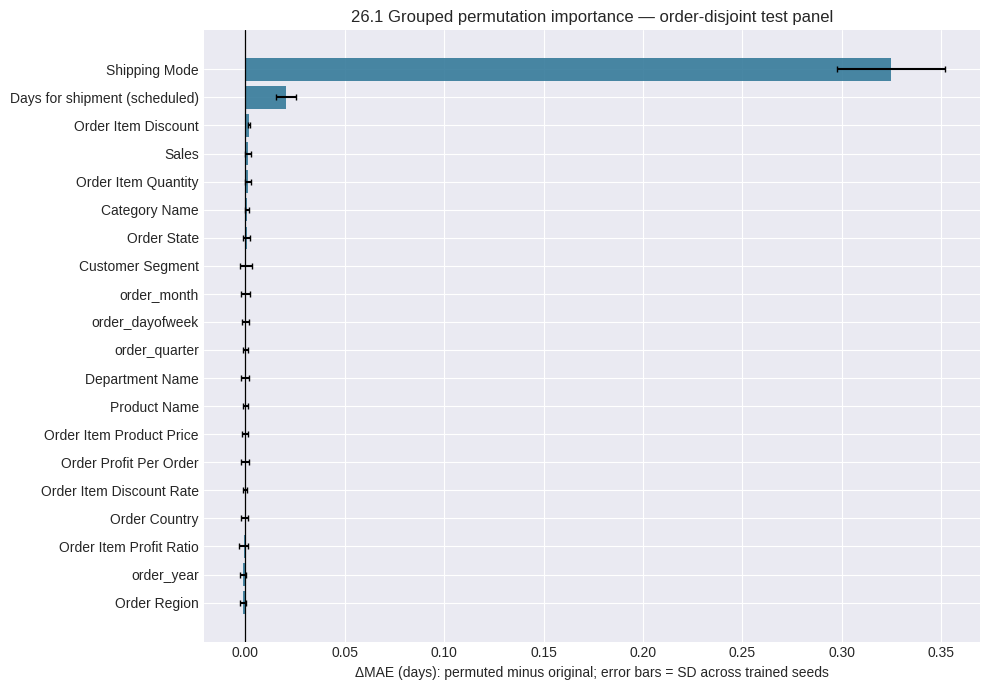

In [ ]:
# Fit only grouped, order-disjoint versions of the EXISTING regression FFNN.
# Retain each model temporarily for permutation + SHAP, then release it.

def ex26_grouped_permutation(model, x_eval, y_eval, baseline_mae, groups, seed):
    rng = ex26_np.random.default_rng(262600 + int(seed))
    rows = []
    n = len(y_eval)
    for group, feature_indices in groups.items():
        # One predict() call per group, all repeated permutations batched.
        batch = ex26_np.tile(x_eval, (ex26_PERMUTATIONS_PER_SEED, 1))
        for repeat in range(ex26_PERMUTATIONS_PER_SEED):
            shuffled_orders = rng.permutation(n)
            block = batch[repeat * n:(repeat + 1) * n]
            block[:, feature_indices] = x_eval[shuffled_orders][:, feature_indices]
        predictions = model.predict(batch, batch_size=1024, verbose=0).reshape(
            ex26_PERMUTATIONS_PER_SEED, n)
        shuffled_mae = ex26_np.mean(ex26_np.abs(predictions - y_eval[None, :]), axis=1)
        for repeat, shuffled_loss in enumerate(shuffled_mae, start=1):
            rows.append({'model_seed': int(seed), 'original_feature': group,
                         'permutation_repeat': repeat, 'baseline_MAE_days': baseline_mae,
                         'shuffled_MAE_days': float(shuffled_loss),
                         'delta_MAE_days': float(shuffled_loss - baseline_mae)})
    return ex26_pd.DataFrame(rows)


def ex26_shap_values(model, x_eval, background, seed):
    # Expected-gradients SHAP is the primary method (differentiable FFNN).
    # Expected gradients for one continuous FFNN output. No silent fallback:
    # switching explainer methods across seeds would invalidate rank-stability comparisons.
    try:
        explainer = ex26_shap.GradientExplainer(model, background)
        values = explainer.shap_values(
            x_eval, nsamples=ex26_SHAP_NSAMPLES, rseed=int(seed))
    except Exception as exc:
        raise RuntimeError(
            'SHAP GradientExplainer failed. Check Keras/TensorFlow/SHAP versions; '
            'do not silently switch algorithms in a cross-seed comparison.'
        ) from exc
    method = 'GradientExplainer (expected gradients)'
    if isinstance(values, list):
        if len(values) != 1:
            raise ValueError(f'Expected one scalar regression output, got {len(values)}.')
        values = values[0]
    values = ex26_np.asarray(values, dtype=float)
    if values.ndim == 3 and values.shape[-1] == 1:
        values = values[:, :, 0]
    if values.shape != x_eval.shape or not ex26_np.isfinite(values).all():
        raise ValueError(f'Unexpected SHAP shape/value: {values.shape} != {x_eval.shape}')
    return values, method


ex26_permutation_frames = []
ex26_shap_rank_frames = []
ex26_shap_observation_frames = []
ex26_model_runs = []
ex26_additivity_rows = []
ex26_explainer_methods = set()

for ex26_seed in ex26_MODEL_SEEDS:
    print(f'Section 26: grouped FFNN | training seed={ex26_seed}', flush=True)
    rv_tf.keras.utils.set_random_seed(int(ex26_seed))
    ex26_model = build_ffnn_stable(input_dim=ex26_arrays['train'].shape[1])
    if ex26_model.output_shape[-1] != 1:
        raise ValueError('Section 26 supports only the source Regression FFNN.')
    ex26_stop = rv_tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=rv_PATIENCE, restore_best_weights=True, verbose=0)
    ex26_history = ex26_model.fit(
        ex26_arrays['train'], rv_y.loc[ex26_split['train']].to_numpy(dtype='float32'),
        validation_data=(ex26_arrays['val'],
                         rv_y.loc[ex26_split['val']].to_numpy(dtype='float32')),
        epochs=rv_EPOCHS, batch_size=rv_BATCH_SIZE,
        shuffle=True, callbacks=[ex26_stop], verbose=0)

    ex26_pred = ex26_model.predict(ex26_X_eval, verbose=0).reshape(-1)
    ex26_mae = float(ex26_np.mean(ex26_np.abs(ex26_pred - ex26_y_eval)))
    assert ex26_np.isfinite(ex26_mae)
    ex26_permutation_frames.append(ex26_grouped_permutation(
        ex26_model, ex26_X_eval, ex26_y_eval, ex26_mae, ex26_groups, ex26_seed))

    # 26.2 values use the SAME model/test panel as the importance in 26.1.
    ex26_sv, ex26_method = ex26_shap_values(
        ex26_model, ex26_X_eval, ex26_X_bg, ex26_seed)
    ex26_explainer_methods.add(ex26_method)
    # GradientExplainer produces Monte Carlo approximations; examine the residual
    # rather than claiming exact additivity or silently discarding large deviations.
    ex26_expected_prediction = float(ex26_model.predict(
        ex26_X_bg, verbose=0).reshape(-1).mean())
    ex26_additivity_residual = (ex26_pred - ex26_expected_prediction
                               - ex26_sv.sum(axis=1))
    ex26_additivity_rows.append({
        'model_seed': int(ex26_seed),
        'mean_abs_residual_days': float(ex26_np.mean(ex26_np.abs(ex26_additivity_residual))),
        'max_abs_residual_days': float(ex26_np.max(ex26_np.abs(ex26_additivity_residual))),
        'rmse_residual_days': float(ex26_np.sqrt(ex26_np.mean(ex26_additivity_residual**2))),
        'background_n': len(ex26_X_bg), 'evaluation_n': len(ex26_X_eval),
        'nsamples': ex26_SHAP_NSAMPLES,
    })
    ex26_group_sv = ex26_np.column_stack([
        ex26_sv[:, indices].sum(axis=1) for indices in ex26_groups.values()
    ])
    ex26_shap_rank_frames.append(ex26_pd.DataFrame({
        'model_seed': int(ex26_seed),
        'original_feature': ex26_names,
        'mean_abs_SHAP_days': ex26_np.mean(ex26_np.abs(ex26_group_sv), axis=0),
        'mean_signed_SHAP_days': ex26_np.mean(ex26_group_sv, axis=0),
        'explainer': ex26_method,
    }))
    ex26_observations = ex26_pd.DataFrame(
        ex26_group_sv, columns=ex26_names)
    ex26_observations.insert(0, 'order_id', ex26_eval_ids)
    ex26_observations.insert(0, 'model_seed', int(ex26_seed))
    ex26_observations['observed_delay_days'] = ex26_y_eval
    ex26_observations['predicted_delay_days'] = ex26_pred
    ex26_shap_observation_frames.append(ex26_observations)
    ex26_model_runs.append({
        'model_seed': int(ex26_seed), 'panel_MAE_days': ex26_mae,
        'epochs_trained': len(ex26_history.history['loss']),
        'best_val_epoch': int(ex26_np.argmin(ex26_history.history['val_loss'])) + 1,
        'shap_explainer': ex26_method,
    })
    del ex26_model, ex26_stop, ex26_history, ex26_pred, ex26_sv, ex26_group_sv
    import gc as ex26_gc
    ex26_gc.collect()

if len(ex26_explainer_methods) > 1:
    raise RuntimeError(
        'Different SHAP algorithms were used across model seeds; '
        'methodological consistency requires one explainer type across all seeds.')

ex26_perm_repeats = ex26_pd.concat(ex26_permutation_frames, ignore_index=True)
ex26_perm_seed = ex26_perm_repeats.groupby(
    ['model_seed', 'original_feature'], as_index=False)['delta_MAE_days'].agg(
        mean_delta_MAE_days='mean', sd_permutations_days='std')
ex26_perm_summary = ex26_perm_seed.groupby('original_feature', as_index=False).agg(
    mean_delta_MAE_days=('mean_delta_MAE_days', 'mean'),
    sd_across_model_seeds_days=('mean_delta_MAE_days', 'std'),
    mean_within_seed_sd_days=('sd_permutations_days', 'mean'))
ex26_perm_summary = ex26_perm_summary.sort_values(
    'mean_delta_MAE_days', ascending=False).reset_index(drop=True)
ex26_perm_summary['permutation_rank'] = ex26_np.arange(1, len(ex26_perm_summary) + 1)
ex26_perm_repeats.to_csv(ex26_OUT / '26_1_permutation_repeats.csv', index=False)
ex26_perm_seed.to_csv(ex26_OUT / '26_1_permutation_by_model_seed.csv', index=False)
ex26_perm_summary.to_csv(ex26_OUT / '26_1_permutation_importance.csv', index=False)
ex26_pd.DataFrame(ex26_model_runs).to_csv(ex26_OUT / '26_grouped_training_runs.csv', index=False)
ex26_additivity = ex26_pd.DataFrame(ex26_additivity_rows)
ex26_additivity.to_csv(ex26_OUT / '26_2_shap_additivity_diagnostics.csv', index=False)
display(ex26_additivity.round(5))

display(ex26_pd.DataFrame(ex26_model_runs).round(5))
display(ex26_perm_summary.head(20).round(5))

ex26_perm_top = ex26_perm_summary.head(min(20, len(ex26_perm_summary))).iloc[::-1]
fig, ax = ex26_plt.subplots(figsize=(10, max(5, len(ex26_perm_top)*0.35)))
ax.barh(ex26_perm_top['original_feature'], ex26_perm_top['mean_delta_MAE_days'],
        xerr=ex26_perm_top['sd_across_model_seeds_days'].fillna(0),
        color='#357a9a', alpha=.9, capsize=2)
ax.axvline(0, color='black', linewidth=.9)
ax.set(xlabel='ΔMAE (days): permuted minus original; error bars = SD across trained seeds',
       title='26.1 Grouped permutation importance — order-disjoint test panel')
fig.tight_layout()
fig.savefig(ex26_OUT / '26_1_grouped_permutation.png', dpi=180)
ex26_plt.show()


## 26.2. SHAP Analysis — FFNN Regression

Compute **expected-gradients SHAP** on the same fixed held-out order panel, with background drawn **exclusively from training orders** (model-agnostic Kernel SHAP is used only if the gradient explainer is incompatible with the installed TF/Keras stack). For each original feature, encoded contributions are summed *before* averaging their absolute magnitudes. This preserves the decomposition over grouped one-hot indicators rather than reporting dummy columns as unrelated predictors.

The signed distribution figure shows the direction and dispersion of each original group's contribution in **predicted days**, conditional on the chosen training reference. Mean absolute magnitudes and perturbation-based ΔMAE are **not directly numerically comparable**.


Only `GradientExplainer` is allowed across seeds. Inspect `26_2_shap_additivity_diagnostics.csv`; Monte Carlo additivity is approximate. Signed group contributions are summed first, followed by absolute-value aggregation.


,original_feature,mean_abs_SHAP_days,sd_across_model_seeds_days,mean_signed_SHAP_days,shap_rank
0,Shipping Mode,0.61804,0.02867,0.19002,1
1,Days for shipment (scheduled),0.15861,0.01281,0.01399,2
2,Department Name,0.03531,0.00366,0.00106,3
3,Type,0.03320,0.00506,0.00315,4
4,Customer Segment,0.02160,0.00258,0.00177,5
5,order_year,0.01508,0.00423,0.00113,6
6,Order Item Discount,0.01487,0.00681,0.00119,7
7,Order Item Quantity,0.01428,0.00149,-0.00009,8
8,order_dayofweek,0.01425,0.00187,0.00455,9
9,order_quarter,0.01424,0.00268,0.00059,10


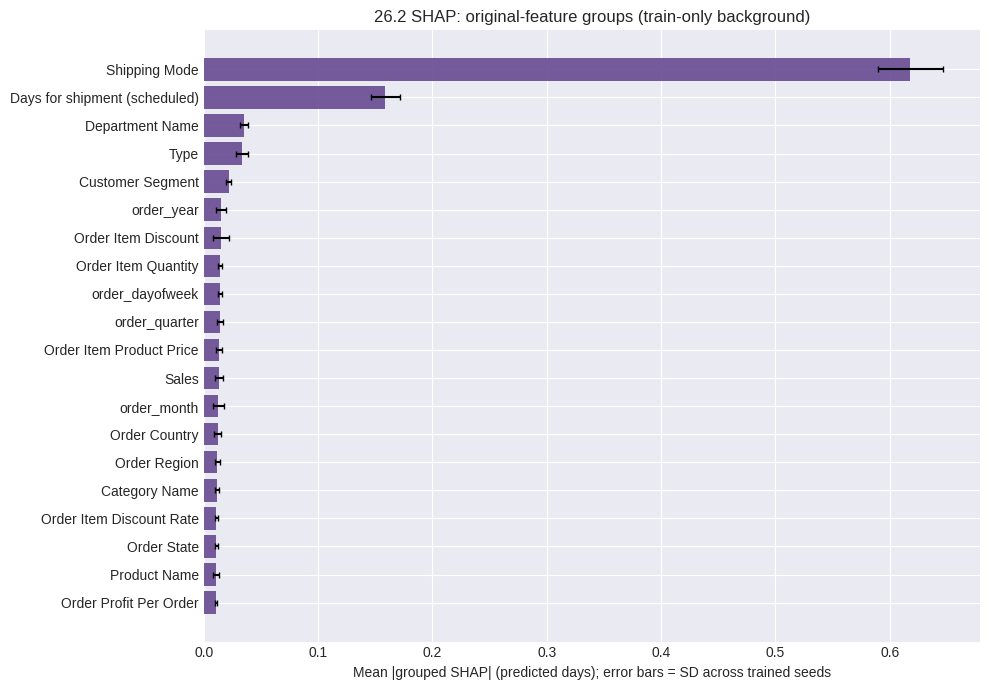

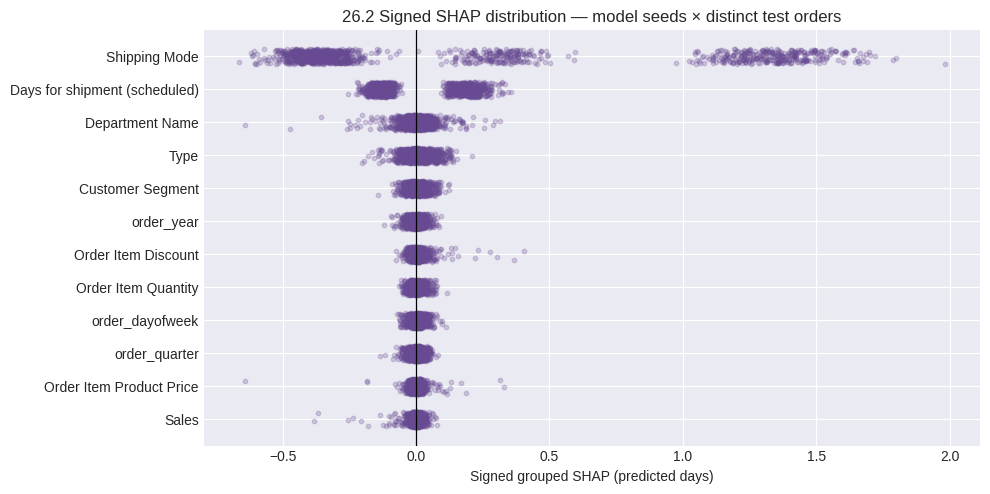

In [ ]:
ex26_shap_seed = ex26_pd.concat(ex26_shap_rank_frames, ignore_index=True)
ex26_shap_observations = ex26_pd.concat(ex26_shap_observation_frames, ignore_index=True)
ex26_shap_summary = ex26_shap_seed.groupby('original_feature', as_index=False).agg(
    mean_abs_SHAP_days=('mean_abs_SHAP_days', 'mean'),
    sd_across_model_seeds_days=('mean_abs_SHAP_days', 'std'),
    mean_signed_SHAP_days=('mean_signed_SHAP_days', 'mean'))
ex26_shap_summary = ex26_shap_summary.sort_values(
    'mean_abs_SHAP_days', ascending=False).reset_index(drop=True)
ex26_shap_summary['shap_rank'] = ex26_np.arange(1, len(ex26_shap_summary) + 1)

ex26_shap_seed.to_csv(ex26_OUT / '26_2_shap_by_model_seed.csv', index=False)
ex26_shap_summary.to_csv(ex26_OUT / '26_2_shap_group_importance.csv', index=False)
ex26_shap_observations.to_csv(ex26_OUT / '26_2_signed_group_shap_values.csv', index=False)
display(ex26_shap_summary.head(20).round(5))

ex26_shap_top = ex26_shap_summary.head(min(20, len(ex26_shap_summary))).iloc[::-1]
fig, ax = ex26_plt.subplots(figsize=(10, max(5, len(ex26_shap_top)*0.35)))
ax.barh(ex26_shap_top['original_feature'], ex26_shap_top['mean_abs_SHAP_days'],
        xerr=ex26_shap_top['sd_across_model_seeds_days'].fillna(0),
        color='#674a92', alpha=.9, capsize=2)
ax.set(xlabel='Mean |grouped SHAP| (predicted days); error bars = SD across trained seeds',
       title='26.2 SHAP: original-feature groups (train-only background)')
fig.tight_layout()
fig.savefig(ex26_OUT / '26_2_grouped_shap_importance.png', dpi=180)
ex26_plt.show()

# Beeswarm-style distribution of signed grouped SHAP values across orders/seeds.
ex26_bee_names = ex26_shap_summary['original_feature'].head(min(12, len(ex26_shap_summary))).tolist()
fig, ax = ex26_plt.subplots(figsize=(10, max(5, len(ex26_bee_names)*0.42)))
ex26_jitter_rng = ex26_np.random.default_rng(2612)
for row_i, group in enumerate(ex26_bee_names[::-1]):
    vals = ex26_shap_observations[group].to_numpy(dtype=float)
    jitter = ex26_jitter_rng.uniform(-.22, .22, len(vals))
    ax.scatter(vals, row_i + jitter, alpha=.24, s=10, color='#674a92', rasterized=True)
ax.set_yticks(range(len(ex26_bee_names)), ex26_bee_names[::-1])
ax.axvline(0, color='black', linewidth=.9)
ax.set(xlabel='Signed grouped SHAP (predicted days)',
       title='26.2 Signed SHAP distribution — model seeds × distinct test orders')
fig.tight_layout()
fig.savefig(ex26_OUT / '26_2_signed_shap_distribution.png', dpi=180)
ex26_plt.show()


## 26.3. Explanation Stability - Spearman Correlation & Top-k Overlap

The underlying order-disjoint train/validation/test split, test-order panel, and SHAP background are held fixed; **the entire FFNN is reinitialized and retrained** for each seed. Within each method, compare the original-feature rankings over every pair of model seeds via Spearman's ρ and `|Top-k(A) ∩ Top-k(B)| / k`. For permutation, each seed's feature score averages its repeated shuffles. With only a few trained seeds, these are descriptive stability diagnostics, **not population confidence intervals or hypothesis tests**.


For `k=5`, report the descriptive overlap together with the chance reference `k/n_features`; neither metric alone is a significance test. Equal features near zero importance can have unstable ranks without making the entire model unstable.


In [ ]:
def ex26_corr(v1, v2):
    a, b = ex26_np.asarray(v1, dtype=float), ex26_np.asarray(v2, dtype=float)
    if len(a) < 2 or not (ex26_np.std(a) > 0 and ex26_np.std(b) > 0):
        return ex26_np.nan
    return float(ex26_spearmanr(a, b).statistic)


def ex26_topk_overlap(first, second, k):
    # Stable tie-breaking avoids dependence on previous row ordering.
    a = set(first.sort_index().sort_values(ascending=False, kind='mergesort').head(k).index)
    b = set(second.sort_index().sort_values(ascending=False, kind='mergesort').head(k).index)
    return len(a & b) / k


ex26_k = min(ex26_TOP_K, len(ex26_groups))
ex26_rank_data = {
    'Grouped permutation': ex26_perm_seed.pivot(
        index='original_feature', columns='model_seed', values='mean_delta_MAE_days'),
    'Grouped SHAP': ex26_shap_seed.pivot(
        index='original_feature', columns='model_seed', values='mean_abs_SHAP_days'),
}
ex26_pairwise_rows = []
for method, wide in ex26_rank_data.items():
    assert not wide.isna().any().any()
    for seed_a, seed_b in ex26_itertools.combinations(ex26_MODEL_SEEDS, 2):
        ex26_pairwise_rows.append({
            'method': method, 'model_seed_a': seed_a, 'model_seed_b': seed_b,
            'spearman_rho': ex26_corr(wide[seed_a], wide[seed_b]),
            'top_k': ex26_k,
            'random_reference_overlap_fraction': ex26_k / len(ex26_groups),
            'top_k_overlap_fraction': ex26_topk_overlap(wide[seed_a], wide[seed_b], ex26_k),
        })

ex26_stability_pairs = ex26_pd.DataFrame(ex26_pairwise_rows)
ex26_stability_summary = ex26_stability_pairs.groupby('method', as_index=False).agg(
    mean_spearman_rho=('spearman_rho', 'mean'),
    min_spearman_rho=('spearman_rho', 'min'),
    mean_top_k_overlap=('top_k_overlap_fraction', 'mean'),
    min_top_k_overlap=('top_k_overlap_fraction', 'min'),
    n_seed_pairs=('spearman_rho', 'size'))
ex26_stability_pairs.to_csv(ex26_OUT / '26_3_rank_stability_pairs.csv', index=False)
ex26_stability_summary.to_csv(ex26_OUT / '26_3_rank_stability_summary.csv', index=False)
display(ex26_stability_pairs.round(4))
display(ex26_stability_summary.round(4))


# Fraction of Top-k expected to overlap for two independent random Top-k selections
# is k / number_of_original_feature_groups; reference only, not a statistical test.
print('Random Top-k overlap reference:', round(ex26_k / len(ex26_groups), 4))
if (ex26_stability_summary['mean_spearman_rho'] < 0.4).any():
    print('Warning: at least one method has low ranking stability; avoid global rank claims.')


,method,model_seed_a,model_seed_b,spearman_rho,top_k,random_reference_overlap_fraction,top_k_overlap_fraction
0,Grouped permutation,42,123,0.1104,5,0.2381,0.4
1,Grouped permutation,42,2026,0.2506,5,0.2381,0.4
2,Grouped permutation,42,7,0.4831,5,0.2381,0.4
3,Grouped permutation,42,99,0.2805,5,0.2381,0.4
4,Grouped permutation,123,2026,0.1974,5,0.2381,0.6
5,Grouped permutation,123,7,0.5130,5,0.2381,0.8
6,Grouped permutation,123,99,0.5844,5,0.2381,0.6
7,Grouped permutation,2026,7,0.0909,5,0.2381,0.6
8,Grouped permutation,2026,99,0.1857,5,0.2381,0.6
9,Grouped permutation,7,99,0.4636,5,0.2381,0.8


,method,mean_spearman_rho,min_spearman_rho,mean_top_k_overlap,min_top_k_overlap,n_seed_pairs
0,Grouped SHAP,0.6631,0.5364,0.86,0.8,10
1,Grouped permutation,0.3160,0.0909,0.56,0.4,10


Random Top-k overlap reference: 0.2381


## 26.4. Cross-Method Comparison — Concordance & Divergence

Compare the **ranks**, not raw magnitudes, because grouped SHAP quantifies attributed prediction shifts whereas grouped permutation quantifies a perturbation-induced **change in prediction error**. The cross-method agreement measures are Spearman's ρ across all original groups and Top-k rank overlap, both overall and **paired by training seed**. Report disagreements transparently; features can receive high SHAP attribution while supplying little incremental predictive value under permutation (or vice versa). These are correlational explanation diagnostics, not causal evidence.


Grouped SHAP and grouped permutation use **different estimands** and can disagree for correlated inputs; compare them descriptively on the same test panel only.


,model_seed,spearman_rho,top_k,random_reference_overlap_fraction,top_k_overlap_fraction
0,42,0.3325,5,0.2381,0.6
1,123,0.2039,5,0.2381,0.6
2,2026,0.3078,5,0.2381,0.6
3,7,0.3039,5,0.2381,0.6
4,99,0.0390,5,0.2381,0.4


,result
comparison,Group SHAP vs grouped permutation (original fe...
mean-score_ranks_spearman_rho,0.357143
mean-score_top_k_overlap_fraction,0.4
top_k,5
random_reference_overlap_fraction,0.238095
n_original_groups,21
trained_model_seeds,"[42, 123, 2026, 7, 99]"
same_test_order_panel_across_methods,True
background_orders_from_training_only,True
explainers_used,[GradientExplainer (expected gradients)]


,original_feature,mean_delta_MAE_days,permutation_rank,mean_abs_SHAP_days,shap_rank,rank_gap_SHAP_minus_perm,absolute_rank_gap
20,Type,-0.0018,21,0.0332,4,-17,17
18,order_year,-0.0011,19,0.0151,6,-13,13
6,Order State,0.0006,7,0.0109,18,11,11
5,Category Name,0.0008,6,0.0115,16,10,10
11,Department Name,-0.0001,12,0.0353,3,-9,9
3,Sales,0.0015,4,0.0131,12,8,8
12,Product Name,-0.0001,13,0.0107,19,6,6
19,Order Region,-0.0014,20,0.0119,15,-5,5
14,Order Profit Per Order,-0.0002,15,0.0107,20,5,5
8,order_month,0.0002,9,0.0127,13,4,4


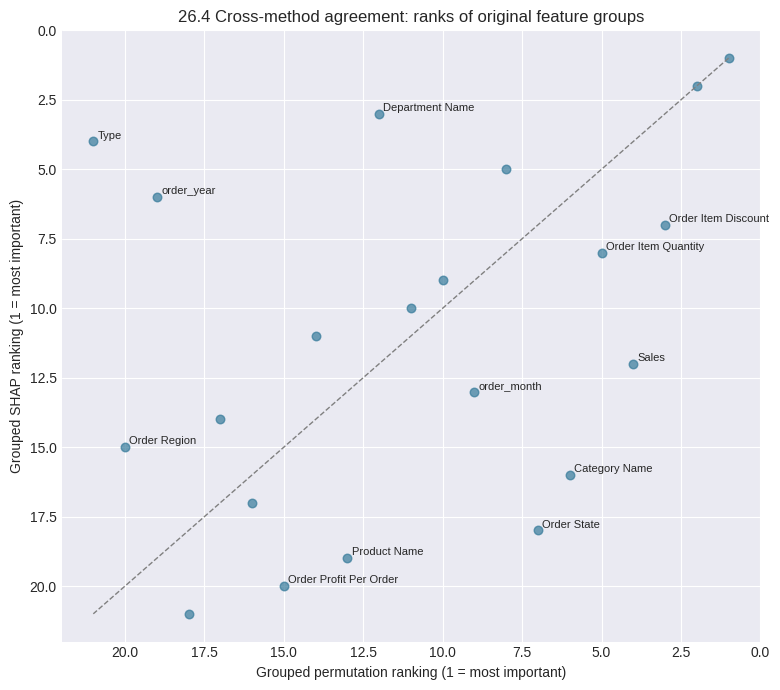

Section 26 artifacts written to: /content/ffnn_v4_regression_validation/section_26_explainability
Note: cross-method concordance is descriptive, not a test of causality or significance.


In [ ]:
ex26_cross = ex26_perm_summary[[
    'original_feature', 'mean_delta_MAE_days', 'permutation_rank'
]].merge(ex26_shap_summary[[
    'original_feature', 'mean_abs_SHAP_days', 'shap_rank'
]], on='original_feature', validate='one_to_one')
ex26_cross['rank_gap_SHAP_minus_perm'] = (
    ex26_cross['shap_rank'] - ex26_cross['permutation_rank'])
ex26_cross['absolute_rank_gap'] = ex26_cross['rank_gap_SHAP_minus_perm'].abs()
ex26_cross = ex26_cross.sort_values('absolute_rank_gap', ascending=False)

ex26_perm_overall = ex26_cross.set_index('original_feature')['mean_delta_MAE_days']
ex26_shap_overall = ex26_cross.set_index('original_feature')['mean_abs_SHAP_days']
ex26_cross_seed_rows = []
for seed in ex26_MODEL_SEEDS:
    p = ex26_rank_data['Grouped permutation'][seed]
    s = ex26_rank_data['Grouped SHAP'][seed]
    ex26_cross_seed_rows.append({
        'model_seed': int(seed), 'spearman_rho': ex26_corr(p, s),
        'top_k': ex26_k,
    'random_reference_overlap_fraction': ex26_k / len(ex26_groups),
        'top_k_overlap_fraction': ex26_topk_overlap(p, s, ex26_k)})
ex26_cross_by_seed = ex26_pd.DataFrame(ex26_cross_seed_rows)
ex26_concordance = {
    'comparison': 'Group SHAP vs grouped permutation (original feature groups)',
    'mean-score_ranks_spearman_rho': ex26_corr(ex26_perm_overall, ex26_shap_overall),
    'mean-score_top_k_overlap_fraction': ex26_topk_overlap(
        ex26_perm_overall, ex26_shap_overall, ex26_k),
    'top_k': ex26_k,
    'random_reference_overlap_fraction': ex26_k / len(ex26_groups),
    'n_original_groups': len(ex26_groups),
    'trained_model_seeds': list(ex26_MODEL_SEEDS),
    'same_test_order_panel_across_methods': True,
    'background_orders_from_training_only': True,
    'explainers_used': sorted(ex26_explainer_methods),
    'interpretation': 'Descriptive, non-causal ranks; explainers have different estimands.'}

ex26_cross.to_csv(ex26_OUT / '26_4_cross_method_feature_ranks.csv', index=False)
ex26_cross_by_seed.to_csv(ex26_OUT / '26_4_cross_method_by_seed.csv', index=False)
with open(ex26_OUT / '26_4_concordance.json', 'w', encoding='utf-8') as f:
    ex26_json.dump(ex26_concordance, f, ensure_ascii=False, indent=2)

display(ex26_cross_by_seed.round(4))
display(ex26_pd.DataFrame([ex26_concordance]).T.rename(columns={0: 'result'}))
display(ex26_cross.head(20).round(4))

fig, ax = ex26_plt.subplots(figsize=(8, 7))
ax.scatter(ex26_cross['permutation_rank'], ex26_cross['shap_rank'],
           s=38, alpha=.7, color='#357a9a')
for feature in ex26_cross.head(min(12, len(ex26_cross)))['original_feature']:
    point = ex26_cross.set_index('original_feature').loc[feature]
    ax.annotate(feature, (point['permutation_rank'], point['shap_rank']),
                xytext=(3, 2), textcoords='offset points', fontsize=8)
ax.plot([1, len(ex26_cross)], [1, len(ex26_cross)],
        linestyle='--', linewidth=1, color='gray')
ax.set(xlabel='Grouped permutation ranking (1 = most important)',
       ylabel='Grouped SHAP ranking (1 = most important)',
       title='26.4 Cross-method agreement: ranks of original feature groups')
ax.invert_xaxis()
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(ex26_OUT / '26_4_cross_method_rank_scatter.png', dpi=180)
ex26_plt.show()

# Do not mutate the original model; check original weight hash when available.
if 'rv_original_model_hash' in globals() and rv_original_model_hash is not None:
    ex26_after_hash = rv_hashlib.sha256(
        b''.join(w.tobytes() for w in model_reg.get_weights())).hexdigest()
    assert ex26_after_hash == rv_original_model_hash, 'Original model weights changed.'

ex26_manifest = {
    'section': 26,
    'training_model': 'build_ffnn_stable (source unchanged)',
    'split': 'section 21 grouped, train/val/test Order ID disjoint',
    'evaluation_unit': 'one sampled item per unique held-out order',
    'trained_model_seeds': list(ex26_MODEL_SEEDS),
    'n_test_orders': int(len(ex26_eval_ids)),
    'n_background_training_orders': int(len(ex26_bg_pos)),
    'n_original_feature_groups': int(len(ex26_groups)),
    'n_encoded_features': int(len(ex26_encoded_columns)),
    'permutations_per_seed_per_group': int(ex26_PERMUTATIONS_PER_SEED),
    'top_k': int(ex26_k),
    'expected_random_top_k_overlap_fraction': float(ex26_k / len(ex26_groups)),
    'shap_mean_abs_additivity_residual_days': float(ex26_additivity['mean_abs_residual_days'].mean()),
    'shap_nsamples': int(ex26_SHAP_NSAMPLES),
    'shap_explainers_used': sorted(ex26_explainer_methods),
    'leakage_policy': 'Split-wise fitting and distinct train/val/test Order Id; original random split not reused',
    'limitations': ['Predictor order-time availability not fully independently verified',
                    'Marginal permutation can break feature dependence',
                    'Fixed representative-item-per-order sample; panel selection affects rankings',
                    'Order dependencies across customers/time may remain',
                    'Ordinal encoder category ranking is an original-model design choice'],
    'original_model_weights_unchanged': True if 'rv_original_model_hash' in globals()
        and rv_original_model_hash is not None else 'not checked'}
with open(ex26_OUT / '26_methodology_manifest.json', 'w', encoding='utf-8') as f:
    ex26_json.dump(ex26_manifest, f, ensure_ascii=False, indent=2)
print(f'Section 26 artifacts written to: {ex26_OUT}')

print('Note: cross-method concordance is descriptive, not a test of causality or significance.')
